# Pairs trading – korrelationsanalys och strategi

Notebooken svarar på två frågor för ett godtyckligt dataset (bred csv: datum + en kolumn per tidsserie):

1. **Finns det något att handla?** Korrelation mellan enskilda tillgångar (avsnitt 2), mellan *korgar* av tillgångar (avsnitt 3) och – det som avgör – om någon spread är mean-reverting (avsnitt 4).
2. **Hur handlar vi det?** En kausal pairs trading-strategi för par och korgar (avsnitt 5), parametersvep och reglage (avsnitt 6), läckagetest och export (avsnitt 7).

**Arbetsgång:** sätt `DATA_PATH` och `FIT_END` i avsnitt 0 → *Run All* → läs slutsatsen i avsnitt 4 → skruva på `PARAMS`.

Konventioner från Lynx: avkastning = prisdifferens, en position daterad $t$ handlas dag $t+1$ och ger avkastning dag $t+2$. Alla nyckeltal räknas med `evaluation.py`, som ska ligga i samma mapp. Inga paket utöver `numpy`, `pandas`, `polars` och `matplotlib` behövs.

In [1]:
from itertools import combinations
from math import comb
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from numpy.lib.stride_tricks import sliding_window_view

notebook_file = globals().get("__vsc_ipynb_file__")
NOTEBOOK_DIR = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))

import evaluation

DATE = "AsOfDate"

# Figurstil: en färg per serie i fast ordning; divergerande skala (röd = negativ, blå = positiv) för korrelation och Sharpe
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("red_gray_blue", ["#b3332f", "#ec9b95", "#f0efec", "#86b6ef", "#1c5cab"])
DIVERGING.set_bad("white")
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=COLORS), "lines.linewidth": 1.3,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False, "legend.fontsize": 8.5,
})
OUTSIDE = dict(loc="upper left", bbox_to_anchor=(1.0, 1.0))      # förklaringsruta till höger om figuren

## 0. Inställningar

Allt som behöver ändras för ett nytt dataset eller en ny strategivariant finns i den här cellen.

In [2]:
# ---------- Data ----------
DATA_PATH   = NOTEBOOK_DIR / "example_prices.csv"    # bred csv: datumkolumn + en kolumn per tidsserie
EXTRA_PATHS = []             # fler csv-filer i samma format med icke-handlade serier (t.ex. makrodata)
DATE_COL    = None           # None = hitta datumkolumnen automatiskt
NON_TRADED  = []             # kolumner i DATA_PATH som bara är information – får aldrig positioner
FIT_END     = "2014-12-31"   # in-sample t.o.m. detta datum, därefter out-of-sample. Datum, eller andel (t.ex. 0.65)
COST        = -0.02          # kostnad per handlad enhet i dagliga standardavvikelser (som evaluation.py)
OUTPUT_PATH = NOTEBOOK_DIR / "pairs_positions.csv"

# ---------- Analys (avsnitt 2–3) ----------
HORIZONS   = (1, 5, 20)      # avkastningshorisonter i dagar
VOL_WINDOW = 100             # fönster för volatilitetsnormalisering av avkastningar
ROLL_CORR  = 250             # fönster för rullande korrelation
MAX_LEG    = 2               # max antal tillgångar per korg i korg-mot-korg-skanningen

# ---------- Urval av spreadar (avsnitt 4) ----------
SCREEN = dict(
    max_basket = 3,          # max serier i en spread: 2 = rena par, 3 = 1 mot 2, 4 = 1 mot 3 eller 2 mot 2
    adf_lags   = 1,          # antal laggar i ADF-testet
)
SELECT = dict(
    top_k      = 3,          # högst så här många spreadar handlas
    hl_min     = 3,          # tillåten halveringstid (dagar): för kort hinner vi inte handla (lagg 2 dagar),
    hl_max     = 250,        #   för lång betyder i praktiken ingen mean reversion
    max_corr   = 0.5,        # max |korrelation| mellan valda spreadar – sållar bort dubbletter
    max_margin = 0.0,        # krav: ADF-t ≤ 5 %-gränsen + max_margin. 0 = nominell signifikans, np.inf = ta alltid top_k
)
N_SURROGATES   = 30          # antal slumpade dataset i signifikanstestet (0 = hoppa över)
MANUAL_SPREADS = None        # t.ex. [("butter", ("cars",)), ("bananas", ("butter", "cars"))] = (y, (x1, x2, ...)); överstyr urvalet

SELECTION   = "fixed"        # "fixed": ett urval på in-sample | "walkforward": nytt urval löpande, bara på historik
FIT_WINDOW  = 1000           # (walkforward) antal dagar historik per urval
REFIT_EVERY = 250            # (walkforward) antal dagar mellan urvalen

# ---------- Strategi (avsnitt 5) ----------
PARAMS = dict(
    beta_window = 500,       # dagar för rullande hedge ratio (OLS). None = all historik
    z_window    = 120,       # dagar för spreadens medelvärde/std i z-värdet (tumregel: minst 3–5 × halveringstiden)
    entry_z     = 1.0,       # gå in när |z| > entry_z
    exit_z      = 0.0,       # gå ur när z är tillbaka vid ±exit_z (0 = medelvärdet, −entry_z = vänd direkt)
    stop_z      = 4.0,       # stop-loss när |z| > stop_z (None = av)
    signal      = "band",    # "band": −1/0/+1 med hysteres | "linear": kontinuerlig position ∝ −z
    vol_window  = 100,       # dagar för spreadens volatilitet (varje spread får samma risk)
    risk_window = 100,       # dagar för portföljens riskskalning till konstant förväntad risk (None = av)
)

## 1. Data

In [3]:
def load_prices(path, date_col=None):
    """Läser en bred csv (datum + en kolumn per serie) → DataFrame med datumindex 'AsOfDate'."""
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]                          # sparat radindex
    known = ("asofdate", "date", "dates", "datum", "time", "timestamp")
    date_col = date_col or next((c for c in df.columns if str(c).lower() in known), df.columns[0])
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.set_index(date_col).sort_index().rename_axis(DATE)
    df = df[~df.index.duplicated(keep="last")].select_dtypes("number").astype(float).ffill()   # luckor fylls framåt
    return df.loc[:, df.nunique() > 1]                                                         # släng konstanta kolumner


def normalized_returns(P, vol_window=100):
    """Dagliga prisdifferenser / rullande volatilitet t.o.m. gårdagen (som i modeling_example)."""
    d = P.diff()
    vol = np.sqrt((d**2).rolling(vol_window, min_periods=vol_window // 2).mean()).shift(1)
    return (d / vol).replace([np.inf, -np.inf], np.nan)

5956 dagar, 2000-01-03 – 2023-01-11 | in-sample 3881, out-of-sample 2075 dagar
5 handlade: ['diamonds', 'butter', 'cars', 'cucumber', 'bananas']


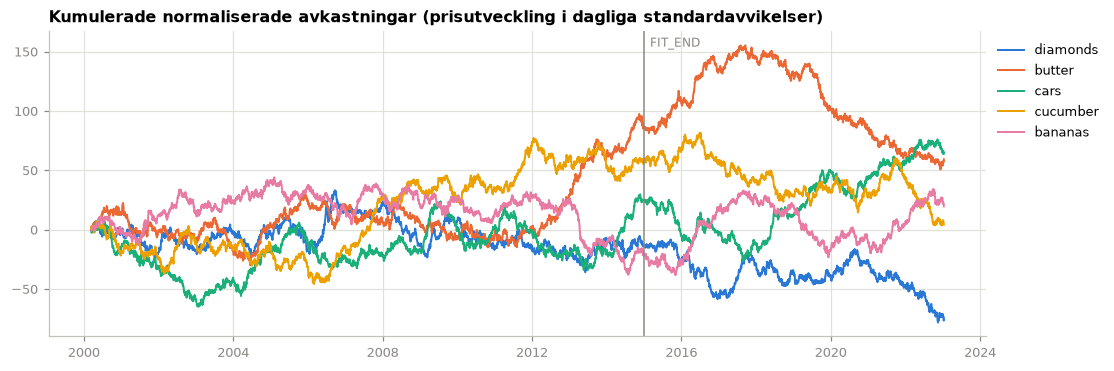

In [4]:
P, info_only = load_prices(DATA_PATH, DATE_COL), list(NON_TRADED)     # P = alla serier
for path in EXTRA_PATHS:
    extra = load_prices(path, DATE_COL)
    P, info_only = P.join(extra, how="left").ffill(), info_only + list(extra.columns)
TRADED = [c for c in P.columns if c not in info_only]                 # serier vi får ta positioner i

if isinstance(FIT_END, float):
    FIT_END = P.index[int(len(P) * FIT_END) - 1]
    print(f"OBS: FIT_END gavs som andel → {FIT_END.date()}. Skriv in datumet i avsnitt 0 innan mer data läggs till.")
FIT_END = pd.Timestamp(FIT_END)
P_IS, P_OOS = P.loc[:FIT_END], P.loc[P.index > FIT_END]
assert len(P_IS) >= 500 and len(P_OOS) >= 250, f"FIT_END måste ligga en bit innanför {P.index[0].date()} – {P.index[-1].date()}"
OOS_START = P_OOS.index[0]
PERIODS = {"hela": (None, None), "in-sample": (None, FIT_END), "out-of-sample": (OOS_START, None)}

R = normalized_returns(P, VOL_WINDOW)                                 # normaliserade dagsavkastningar
R_IS, R_OOS = R.loc[:FIT_END].dropna(), R.loc[OOS_START:].dropna()

print(f"{len(P)} dagar, {P.index[0].date()} – {P.index[-1].date()} | in-sample {len(P_IS)}, out-of-sample {len(P_OOS)} dagar")
print(f"{len(TRADED)} handlade: {TRADED}" + (f"\n{len(info_only)} icke-handlade: {info_only}" if info_only else ""))

fig, ax = plt.subplots(figsize=(11, 3.6))
many = P.shape[1] > len(COLORS)
for c in P.columns:
    ax.plot(R.index, R[c].cumsum(), label=c, **({"color": COLORS[0], "alpha": 0.5, "lw": 0.8} if many else {}))
ax.axvline(FIT_END, color=MUTED, lw=1)
ax.annotate("FIT_END", (FIT_END, 1), xycoords=("data", "axes fraction"), xytext=(4, -10), textcoords="offset points",
            fontsize=8, color=MUTED)
ax.set_title("Kumulerade normaliserade avkastningar (prisutveckling i dagliga standardavvikelser)")
if not many:
    ax.legend(**OUTSIDE)
plt.show()

## 2. Korrelation mellan enskilda tillgångar

Korrelationen mäts på volatilitetsnormaliserade avkastningar över flera horisonter. Ökar den med horisonten har tillgångarna en gemensam långsam komponent som det dagliga bruset döljer – ett första tecken på att spreaden kan vara mean-reverting. Heatmaps skattas på in-sample; tabellen visar även out-of-sample och hur mycket korrelationen rör sig över tid.

In [5]:
def horizon_corr(R, h):
    """Korrelation mellan h-dagarsavkastningar (överlappande summor av dagsavkastningar)."""
    return R.rolling(h).sum().corr()


def cluster_order(C):
    """Ordnar tillgångarna efter vinkeln i de två största egenvektorerna, så att korrelerade hamnar intill varandra."""
    _, v = np.linalg.eigh(C.fillna(0).to_numpy())
    e1 = v[:, -1] * (np.sign(v[:, -1].sum()) or 1)
    return list(C.index[np.argsort(np.arctan2(v[:, -2], e1))])


def plot_heatmaps(mats, titles, label):
    """Heatmaps bredvid varandra med gemensam, symmetrisk färgskala. Diagonalen utelämnas för kvadratiska matriser."""
    mats = [m.astype(float) for m in mats]
    square = all(list(m.index) == list(m.columns) for m in mats)
    arrs = [np.where(np.eye(len(m), dtype=bool), np.nan, m.to_numpy()) if square else m.to_numpy() for m in mats]
    vmax = max(0.2, np.ceil(10 * np.nanmax([np.nanmax(np.abs(a)) for a in arrs])) / 10)
    rows, cols = arrs[0].shape
    cell = min(0.62, (16 - 1.6 * len(mats)) / (len(mats) * cols))                 # rutstorlek i tum; hela figuren ≤ 16 tum bred
    font = float(np.clip(cell * 54, 4, 8.5))
    size = (len(mats) * (1.6 + cell * cols), 1.3 + cell * rows)
    fig, axes = plt.subplots(1, len(mats), figsize=size, squeeze=False, layout="constrained")
    for ax, m, a, title in zip(axes[0], mats, arrs, titles):
        im = ax.imshow(a, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
        ax.set_xticks(range(cols), m.columns, rotation=90, fontsize=font)
        ax.set_yticks(range(rows), m.index, fontsize=font)
        ax.set_title(title)
        ax.grid(False)
        for i, j in np.ndindex(rows, cols) if cell > 0.45 else ():                # siffror bara om de får plats
            if not np.isnan(a[i, j]):
                ax.text(j, i, f"{a[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if abs(a[i, j]) > 0.6 * vmax else INK)
    fig.colorbar(im, ax=axes, shrink=0.85, label=label, pad=0.02)
    return fig


def pair_table(R_is, R_oos, R_all, horizons, roll):
    """En rad per par: korrelation per horisont (in-sample), dagskorrelation out-of-sample och spännvidd i rullande korrelation."""
    C, C_oos = {h: horizon_corr(R_is, h) for h in horizons}, R_oos.corr()
    rows = {}
    for a, b in combinations(R_is.columns, 2):
        rolling = R_all[a].rolling(roll).corr(R_all[b])
        rows[f"{a} ~ {b}"] = {**{f"rho_{h}d": C[h].loc[a, b] for h in horizons}, "rho_1d_oos": C_oos.loc[a, b],
                               "rullande_min": rolling.min(), "rullande_max": rolling.max()}
    table = pd.DataFrame(rows).T
    return table.reindex(table.iloc[:, 0].abs().sort_values(ascending=False).index)

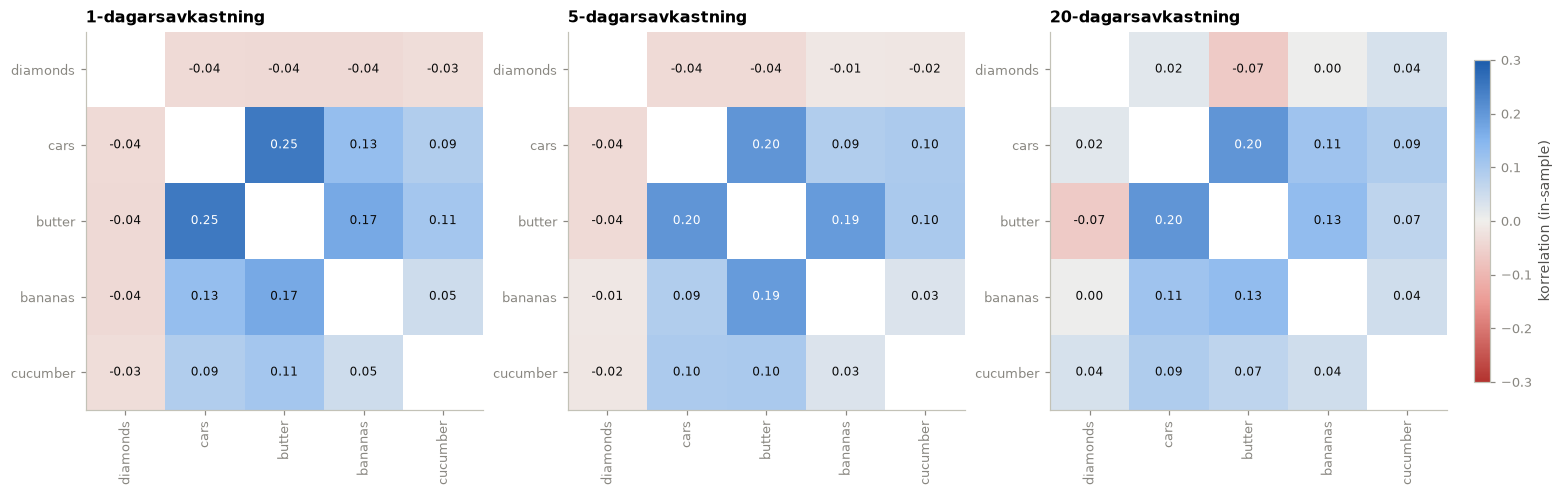

,rho_1d,rho_5d,rho_20d,rho_1d_oos,rullande_min,rullande_max
butter ~ cars,0.249,0.204,0.202,0.238,0.016,0.393
butter ~ bananas,0.171,0.193,0.133,0.167,-0.008,0.294
cars ~ bananas,0.127,0.087,0.113,0.130,-0.006,0.299
butter ~ cucumber,0.106,0.097,0.070,0.090,-0.098,0.239
cars ~ cucumber,0.089,0.095,0.091,0.072,-0.072,0.220
cucumber ~ bananas,0.047,0.029,0.045,0.043,-0.091,0.212
diamonds ~ bananas,-0.040,-0.012,0.004,-0.031,-0.170,0.109
diamonds ~ butter,-0.038,-0.037,-0.065,-0.103,-0.215,0.135
diamonds ~ cars,-0.036,-0.036,0.020,-0.041,-0.231,0.122
diamonds ~ cucumber,-0.031,-0.016,0.037,-0.018,-0.216,0.174


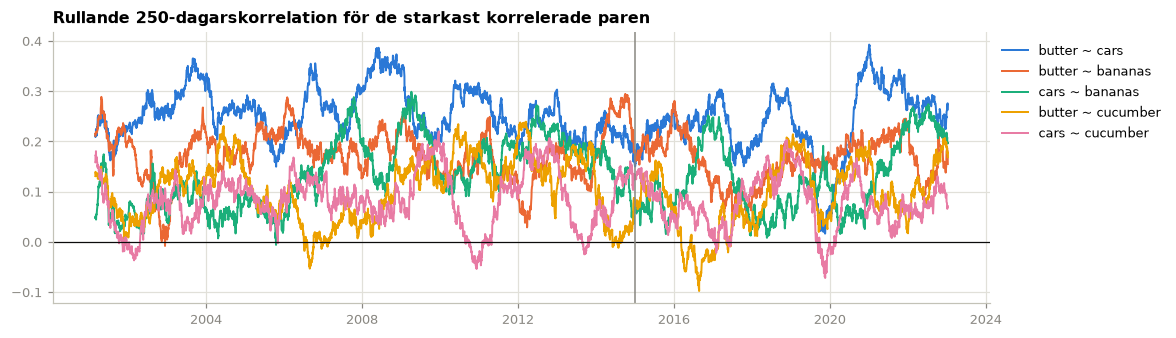

In [6]:
corr = {h: horizon_corr(R_IS, h) for h in HORIZONS}
order = cluster_order(corr[HORIZONS[0]])
plot_heatmaps([corr[h].loc[order, order] for h in HORIZONS], [f"{h}-dagarsavkastning" for h in HORIZONS], "korrelation (in-sample)")
plt.show()

pairs = pair_table(R_IS, R_OOS, R, HORIZONS, ROLL_CORR)
display(pairs.head(15).round(3))

fig, ax = plt.subplots(figsize=(11, 3.2))
for name in pairs.index[:5]:
    a, b = name.split(" ~ ")
    ax.plot(R.index, R[a].rolling(ROLL_CORR).corr(R[b]), label=name)
ax.axhline(0, color=INK, lw=0.8)
ax.axvline(FIT_END, color=MUTED, lw=1)
ax.set_title(f"Rullande {ROLL_CORR}-dagarskorrelation för de starkast korrelerade paren")
ax.legend(**OUTSIDE)
plt.show()

## 3. Korgar mot korgar

Två frågor om linjärkombinationer av avkastningar:

* **En tillgång mot en korg av alla andra.** $R_i^2 = 1 - 1/(C^{-1})_{ii}$ är förklaringsgraden när tillgång $i$ regresseras på övriga ($C$ = korrelationsmatrisen).
* **Korg mot korg.** För två disjunkta korgar $A$ och $B$ ger kanonisk korrelationsanalys (CCA) vikterna som maximerar $\rho = \mathrm{corr}(a^\top r_A,\; b^\top r_B)$. `lyft` = $\rho$ minus det bästa enskilda paret mellan korgarna, dvs. vad kombinationen tillför. Vikterna skattas in-sample och `rho_oos` mäter samma korgar out-of-sample.

Vikterna avser normaliserade avkastningar (riskvikter) och är skalade så att $\sum|w| = 1$ per korg.

In [7]:
def cca(C, A, B):
    """Första kanoniska korrelationen mellan korgarna A och B (positionsindex) givet korrelationsmatrisen C.
    Returnerar (rho, a, b) där vikterna a, b maximerar corr(a·r_A, b·r_B)."""
    La, Lb = np.linalg.cholesky(C[np.ix_(A, A)]), np.linalg.cholesky(C[np.ix_(B, B)])
    U, s, Vt = np.linalg.svd(np.linalg.solve(La, C[np.ix_(A, B)]) @ np.linalg.inv(Lb).T)   # korskorrelation, vitade korgar
    a, b = np.linalg.solve(La.T, U[:, 0]), np.linalg.solve(Lb.T, Vt[0])
    sign = np.sign(a[np.abs(a).argmax()])
    return s[0], sign * a / np.abs(a).sum(), sign * b / np.abs(b).sum()


def basket_text(names, weights):
    """'0.62·butter + 0.38·cars' – vikt 1 skrivs utan siffra, vikt 0 utelämnas."""
    terms = [("−" if w < 0 else "+", n if f"{abs(w):.3g}" == "1" else f"{abs(w):.3g}·{n}")
             for n, w in zip(names, weights) if w != 0]
    text = " ".join(f"{sign} {term}" for sign, term in terms)
    return (text[2:] if text.startswith("+") else text) or "–"


def cca_scan(R_is, R_oos, max_leg=2, h=1, max_splits=300_000):
    """Alla uppdelningar (A, B) med högst max_leg tillgångar per korg: maximal korrelation mellan korgarnas h-dagarsavkastningar."""
    names, n = list(R_is.columns), R_is.shape[1]
    C, C_oos = horizon_corr(R_is, h).to_numpy(), horizon_corr(R_oos, h).to_numpy()
    count = lambda k: sum(comb(n, a) * comb(n - a, b) // (1 + (a == b)) for a in range(1, k + 1) for b in range(a, k + 1))
    while max_leg > 1 and count(max_leg) > max_splits:                 # för många uppdelningar → mindre korgar
        max_leg -= 1
        print(f"OBS: för många uppdelningar med {n} serier – skannar med max_leg = {max_leg}.")
    splits = [(list(A), list(B)) for ka in range(1, max_leg + 1) for kb in range(ka, max_leg + 1)
              for A in combinations(range(n), ka)
              for B in combinations([i for i in range(n) if i not in A], kb) if ka < kb or A < B]
    rows = []
    for A, B in splits:
        try:
            rho, a, b = cca(C, A, B)
        except np.linalg.LinAlgError:                                  # perfekt korrelerade serier i en korg
            continue
        rho_oos = a @ C_oos[np.ix_(A, B)] @ b / np.sqrt((a @ C_oos[np.ix_(A, A)] @ a) * (b @ C_oos[np.ix_(B, B)] @ b))
        best_pair = np.abs(C[np.ix_(A, B)]).max()
        rows.append({"korg_A": basket_text([names[i] for i in A], a), "korg_B": basket_text([names[i] for i in B], b),
                     "n": len(A) + len(B), "rho": rho, "rho_oos": rho_oos, "bästa_par": best_pair, "lyft": rho - best_pair})
    return pd.DataFrame(rows).sort_values("rho", ascending=False).reset_index(drop=True)

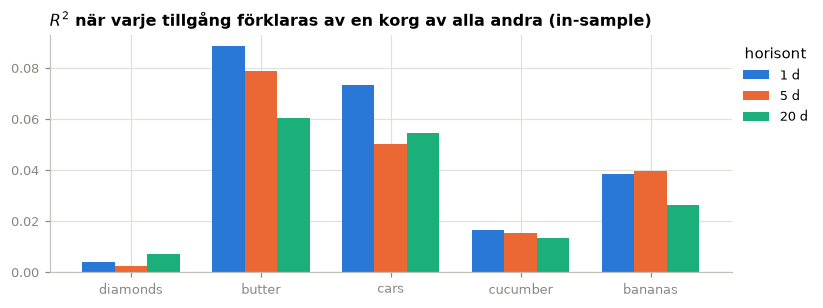

55 uppdelningar, horisont 1 d. Störst korrelation mellan korgar:


,korg_A,korg_B,n,rho,rho_oos,bästa_par,lyft
0,0.809·butter + 0.191·cucumber,0.625·cars + 0.375·bananas,4,0.293,0.280,0.249,0.044
1,− 0.119·diamonds + 0.881·butter,0.616·cars + 0.384·bananas,4,0.288,0.275,0.249,0.040
2,butter,0.62·cars + 0.38·bananas,3,0.286,0.275,0.249,0.037
3,0.734·butter + 0.266·bananas,0.746·cars + 0.254·cucumber,4,0.277,0.266,0.249,0.028
4,− 0.126·diamonds + 0.874·cars,0.722·butter + 0.278·bananas,4,0.266,0.265,0.249,0.017
5,− 0.114·diamonds + 0.886·butter,0.737·cars + 0.263·cucumber,4,0.265,0.249,0.249,0.016
6,cars,0.729·butter + 0.271·bananas,3,0.263,0.255,0.249,0.014
7,butter,0.741·cars + 0.259·cucumber,3,0.263,0.249,0.249,0.014
8,− 0.119·diamonds + 0.881·cars,0.787·butter + 0.213·cucumber,4,0.259,0.253,0.249,0.010
9,cars,0.793·butter + 0.207·cucumber,3,0.257,0.243,0.249,0.008


In [8]:
r2 = pd.DataFrame({f"{h} d": 1 - 1 / np.diag(np.linalg.pinv(corr[h].to_numpy())) for h in HORIZONS}, index=corr[HORIZONS[0]].index)
ax = r2.plot.bar(figsize=(max(8, 0.9 * len(r2) + 2), 2.8), width=0.75, rot=0 if len(r2) <= 8 else 90)
ax.set_title("$R^2$ när varje tillgång förklaras av en korg av alla andra (in-sample)")
ax.legend(title="horisont", **OUTSIDE)
plt.show()

scan = cca_scan(R_IS, R_OOS, MAX_LEG, h=HORIZONS[0])
print(f"{len(scan)} uppdelningar, horisont {HORIZONS[0]} d. Störst korrelation mellan korgar:")
display(scan.head(12).round(3))

## 4. Vilka spreadar är mean-reverting?

Hög korrelation räcker inte: spreaden mellan två korrelerade slumpvandringar är själv en slumpvandring. Pairs trading kräver **kointegration** – att en linjärkombination av *priserna* är stationär. För varje delmängd med 2…`max_basket` serier skattas (Engle–Granger, på in-sample)

$$y_t = \alpha + \beta^\top x_t + s_t$$

där residualen $s_t$ är spreaden. Varje serie i delmängden provas som $y$ och den bästa behålls. Serier med negativt $\beta$ hamnar på samma sida som $y$, så varje spread är en **korg mot en korg**.

| kolumn | betydelse |
|---|---|
| `long`, `short` | de två korgarna: spread = `long` − `short` (+ konstant). Minustecken i `short` = serien samvarierar negativt med $y$, så spreaden äger båda |
| `adf_t` | ADF-statistikan för $s_t$ – mer negativ = starkare mean reversion |
| `margin` | `adf_t` minus 5 %-gränsen för antalet serier (MacKinnon: −3.34 för par, −3.74 för tre, −4.10 för fyra). Negativ = nominellt signifikant |
| `half_life` | halveringstid i dagar från AR(1), $-\ln 2/\ln(1+b)$. Bör vara klart längre än exekveringslaggen på 2 dagar |
| `rho_1d`, `rho_20d` | korrelation mellan korgarnas 1- och 20-dagarsförändringar |
| `adf_t_oos`, `half_life_oos` | samma mått **out-of-sample med vikterna frysta** – här är 5 %-gränsen −2.86 |

**Multipla tester.** Med många kandidater ser alltid någon bra ut av en slump. Därför körs samma sökning på slumpade dataset där dagarna i avkastningsmatrisen kastats om: korrelationen mellan tillgångar samma dag är kvar, men all mean reversion är borta. Ligger vår bästa kandidat inte tydligt utanför den fördelningen finns inget stöd för pairs trading.

In [9]:
CV5 = {1: -2.86, 2: -3.34, 3: -3.74, 4: -4.10, 5: -4.42, 6: -4.71, 7: -4.98}   # MacKinnon (2010), 5 %, med konstant


def adf_t(x, lags=1, const=False):
    """t-statistikan för γ i ADF-regressionen  Δx_t = γ·x_{t−1} + Σ φ_i·Δx_{t−i} (+ c) + ε."""
    dx = np.diff(x)
    X = np.column_stack([x[lags:-1]] + [dx[lags - i:-i] for i in range(1, lags + 1)]
                        + ([np.ones(len(dx) - lags)] if const else []))
    y = dx[lags:]
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    resid = y - X @ b
    return b[0] / np.sqrt(resid @ resid / (len(y) - X.shape[1]) * XtX_inv[0, 0])


def half_life(x):
    """Halveringstid (dagar) från AR(1):  Δx_t = a + b·x_{t−1} + ε  →  −ln 2 / ln(1 + b)."""
    lag = x[:-1] - x[:-1].mean()
    b = lag @ np.diff(x) / (lag @ lag)
    return -np.log(2) / np.log1p(b) if -1 < b < 0 else np.inf


def split_legs(w, i):
    """Delar spreadvikterna w (y har index i och vikt 1) i två korgar så att spread = long − short.
    Positiva vikter → long, negativa → short. Saknas negativa vikter jämförs y med sin (negativt viktade) korg."""
    if (w < 0).any():
        return np.maximum(w, 0), np.maximum(-w, 0)
    e = np.eye(len(w))[i]
    return e, e - w


def screen_spreads(P_fit, P_val=None, traded=None, max_basket=3, adf_lags=1, min_obs=250):
    """Engle–Granger på alla delmängder med 2..max_basket serier; en rad per delmängd (bästa beroende variabel y).
    P_fit: statisk OLS  y = α + β·x + s  och ADF på s.  P_val (valfri): samma vikter, ADF med konstant på spreaden."""
    names = list(P_fit.columns)
    is_traded = np.isin(names, names if traded is None else list(traded))
    A, B = P_fit.to_numpy(), None if P_val is None else P_val.to_numpy()
    rows = []
    for m in range(2, max_basket + 1):
        for idx in combinations(range(len(names)), m):
            idx = list(idx)
            F = A[:, idx]
            F = F[~np.isnan(F).any(axis=1)]
            if len(F) < min_obs or not is_traded[idx].any():           # för lite data, eller inget i delmängden går att handla
                continue
            mu, S = F.mean(axis=0), np.cov(F, rowvar=False)
            best = None
            for i in range(m):                                         # prova varje serie som beroende variabel y
                J = [j for j in range(m) if j != i]
                try:
                    beta = np.linalg.solve(S[np.ix_(J, J)], S[J, i])
                except np.linalg.LinAlgError:
                    continue
                w = np.zeros(m)
                w[i], w[J] = 1.0, -beta                                # spread = y − β·x
                s = (F - mu) @ w
                t = adf_t(s, adf_lags)
                if best is None or t < best[0]:
                    best = (t, i, w, s)
            if best is None:
                continue
            t, i, w, s = best
            sub = [names[k] for k in idx]
            w_long, w_short = split_legs(w, i)
            U, V = F @ w_long, F @ w_short                             # de två korgarna: spread = U − V (+ konstant)
            row = {"y": sub[i], "xs": tuple(c for c in sub if c != sub[i]), "n": m, "weights": dict(zip(sub, w)),
                   "long": basket_text(sub, w_long), "short": basket_text(sub, w_short),
                   "adf_t": t, "margin": t - CV5[m], "half_life": half_life(s)}
            for h in (1, 20):
                row[f"rho_{h}d"] = np.corrcoef(U[h:] - U[:-h], V[h:] - V[:-h])[0, 1]
            if B is not None:
                G = B[:, idx]
                G = G[~np.isnan(G).any(axis=1)]
                if len(G) >= min_obs:
                    row["adf_t_oos"], row["half_life_oos"] = adf_t(G @ w, adf_lags, const=True), half_life(G @ w)
            rows.append(row)
    cols = ["y", "xs", "n", "weights", "long", "short", "adf_t", "margin", "half_life", "rho_1d", "rho_20d",
            "adf_t_oos", "half_life_oos"]
    return pd.DataFrame(rows, columns=cols).sort_values("margin").reset_index(drop=True)


def select_spreads(cands, P_fit, top_k=3, hl_min=3, hl_max=250, max_corr=0.5, max_margin=0.0):
    """Väljer de top_k bästa kandidaterna (lägst margin) som klarar kraven och inte liknar en redan vald spread."""
    ok = cands[cands.half_life.between(hl_min, hl_max) & (cands.margin <= max_margin)]
    chosen, changes = [], []
    for row in ok.itertuples():
        w = pd.Series(row.weights)
        change = (P_fit[list(w.index)] * w).sum(axis=1, skipna=False).diff()      # spreadens dagliga förändring
        if all(abs(change.corr(other)) < max_corr for other in changes):
            chosen.append((row.y, row.xs))
            changes.append(change)
        if len(chosen) == top_k:
            break
    return chosen


def surrogate_best(P_fit, n, hl_min=3, hl_max=250, seed=0, **screen):
    """Bästa margin i n slumpade dataset: avkastningsmatrisens rader (dagar) permuteras och kumuleras till nya priser."""
    rng = np.random.default_rng(seed)
    base = P_fit.dropna()
    d = base.diff().dropna().to_numpy()
    best = []
    for _ in range(n):
        fake = pd.DataFrame(base.iloc[0].to_numpy() + np.cumsum(rng.permutation(d), axis=0), columns=base.columns)
        c = screen_spreads(fake, **screen)
        best.append(c.margin[c.half_life.between(hl_min, hl_max)].min())
    return np.array(best)[~np.isnan(best)]                             # NaN = ingen kandidat med godkänd halveringstid

,n,long,short,adf_t,margin,half_life,rho_1d,rho_20d,adf_t_oos,half_life_oos
0,2,diamonds,− 0.681·cucumber,-4.05,-0.71,93.45,0.03,-0.04,-0.71,849.23
1,3,diamonds + 0.674·cucumber,0.0464·bananas,-4.12,-0.38,89.56,-0.02,0.03,-0.71,923.63
2,3,diamonds + 0.686·cucumber,0.018·cars,-4.06,-0.32,93.05,-0.02,-0.00,-0.64,956.11
3,3,diamonds,− 0.0325·butter − 0.668·cucumber,-4.05,-0.31,93.43,0.03,-0.03,-0.59,1040.97
4,2,bananas,− 1.1·butter,-2.85,0.49,167.90,-0.16,-0.18,-1.63,465.97
5,2,diamonds,− 0.191·butter,-2.81,0.53,196.01,0.03,0.12,-0.53,1086.50
6,2,diamonds,0.0637·bananas,-2.75,0.59,204.42,-0.03,0.03,-1.25,451.47
7,2,diamonds,− 0.0653·cars,-2.70,0.64,214.06,0.04,0.03,-1.58,292.90
8,3,bananas,− butter − 0.372·cars,-2.93,0.81,152.24,-0.18,-0.17,-1.72,390.59
9,3,1.18·butter + bananas,0.333·cucumber,-2.90,0.84,161.26,0.08,0.06,-1.63,475.87


20 kandidater. Nominellt signifikanta (5 %) in-sample med godkänd halveringstid: 4, varav även out-of-sample: 0.


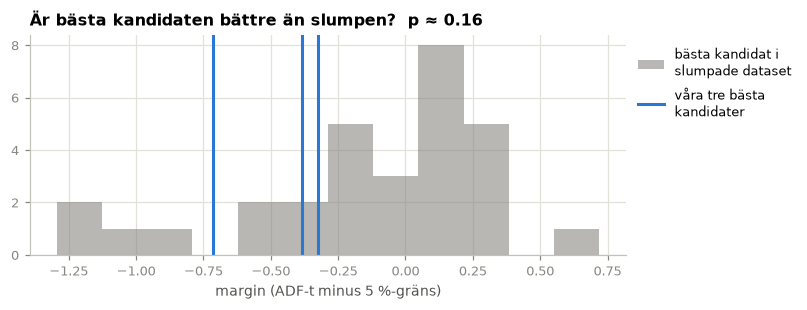

5 %-kvantil för bästa slumpkandidat: -1.15. Sätt SELECT['max_margin'] dit för att bara handla spreadar som slår slumpen.
→ INGET stöd för pairs trading i detta dataset: de bästa spreadarna är inte bättre än vad slumpen ger.


In [10]:
n_subsets = sum(comb(P.shape[1], m) for m in range(2, SCREEN["max_basket"] + 1))
if n_subsets * (1 + N_SURROGATES) > 150_000:
    print(f"OBS: {n_subsets} delmängder × {1 + N_SURROGATES} körningar tar ca {n_subsets * (1 + N_SURROGATES) / 75_000:.0f} min – "
          "minska max_basket eller N_SURROGATES om det går för långsamt.")

cands = screen_spreads(P_IS, P_OOS, traded=TRADED, **SCREEN)
ok = cands[cands.half_life.between(SELECT["hl_min"], SELECT["hl_max"])]
display(cands.drop(columns=["y", "xs", "weights"]).head(15).round(2))

n_is = int((ok.margin < 0).sum())
n_both = int(((ok.margin < 0) & (ok.adf_t_oos < CV5[1])).sum())
print(f"{len(cands)} kandidater. Nominellt signifikanta (5 %) in-sample med godkänd halveringstid: {n_is}, "
      f"varav även out-of-sample: {n_both}.")

beats_chance = False
null = surrogate_best(P_IS, N_SURROGATES, SELECT["hl_min"], SELECT["hl_max"], traded=TRADED, **SCREEN) if len(ok) else []
if len(null):
    p_best = (1 + (null <= ok.margin.min()).sum()) / (1 + N_SURROGATES)
    beats_chance = ok.margin.min() < np.quantile(null, 0.05)
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.hist(null, bins=12, color=MUTED, alpha=0.6, label="bästa kandidat i\nslumpade dataset")
    for k, m in enumerate(ok.margin.head(3)):
        ax.axvline(m, color=COLORS[0], lw=2, label="våra tre bästa\nkandidater" if k == 0 else None)
    ax.set_xlabel("margin (ADF-t minus 5 %-gräns)")
    ax.set_title(f"Är bästa kandidaten bättre än slumpen?  p ≈ {p_best:.2f}")
    ax.legend(**OUTSIDE)
    plt.show()
    print(f"5 %-kvantil för bästa slumpkandidat: {np.quantile(null, 0.05):.2f}. "
          "Sätt SELECT['max_margin'] dit för att bara handla spreadar som slår slumpen.")

if not N_SURROGATES:
    print("(Slumptestet är avstängt: N_SURROGATES = 0.)")
if n_both and beats_chance:
    print("→ STÖD för pairs trading: bästa kandidaten slår slumpen och det finns spreadar som håller out-of-sample.")
elif n_both or beats_chance:
    print("→ SVAGT stöd: något ser mean-reverting ut, men klarar inte både slumptestet och out-of-sample. Var försiktig.")
else:
    print("→ INGET stöd för pairs trading i detta dataset: de bästa spreadarna är inte bättre än vad slumpen ger.")

### Valda spreadar

De högst `top_k` bästa kandidaterna som klarar kraven i `SELECT` väljs (eller `MANUAL_SPREADS`). Figuren visar de två korgarna i prisenheter och spreaden i in-sample-standardavvikelser, med vikterna frysta vid `FIT_END`. Fortsätter spreaden att pendla kring noll till höger om linjen håller sambandet out-of-sample.

In [11]:
def as_spread(s):
    """Normaliserar (y, xs) så att xs alltid är en tuple."""
    return (s[0], (s[1],) if isinstance(s[1], str) else tuple(s[1]))


def spread_name(s):
    return f"{s[0]} ~ {' + '.join(s[1])}"


def plot_static_spreads(P, spreads, fit_end):
    """Per spread: de två korgarna (vänster) och spreaden med in-sample-vikter (höger)."""
    fig, axes = plt.subplots(len(spreads), 2, figsize=(12, 2.5 * len(spreads)), squeeze=False, layout="constrained")
    for (ax1, ax2), (y, xs) in zip(axes, spreads):
        D = P[[y, *xs]].dropna()
        F = D.loc[:fit_end]
        beta = np.linalg.lstsq(np.column_stack([np.ones(len(F)), F[list(xs)]]), F[y], rcond=None)[0]
        w_long, w_short = split_legs(np.r_[1.0, -beta[1:]], 0)
        U, V = D @ w_long, D @ w_short + beta[0]
        s = (U - V) / (U - V).loc[:fit_end].std()
        t_is, t_oos = adf_t(s.loc[:fit_end].to_numpy()), adf_t(s.loc[s.index > fit_end].to_numpy(), const=True)
        ax1.plot(U, label=basket_text(D.columns, w_long))
        ax1.plot(V, label=basket_text(D.columns, w_short) + f" {beta[0]:+.0f}")
        ax1.legend(loc="best")
        ax1.set_title(f"{spread_name((y, xs))}: korg mot korg")
        ax2.plot(s, color=COLORS[0], lw=0.9)
        ax2.axhline(0, color=INK, lw=0.8)
        ax2.set_title(f"spread (in-sample σ) – ADF-t in-sample {t_is:.1f}, out-of-sample {t_oos:.1f}")
        for ax in (ax1, ax2):
            ax.axvline(fit_end, color=MUTED, lw=1)
    return fig

Valda spreadar (klistra in som MANUAL_SPREADS för att frysa urvalet):
 [('diamonds', ('cucumber',))]


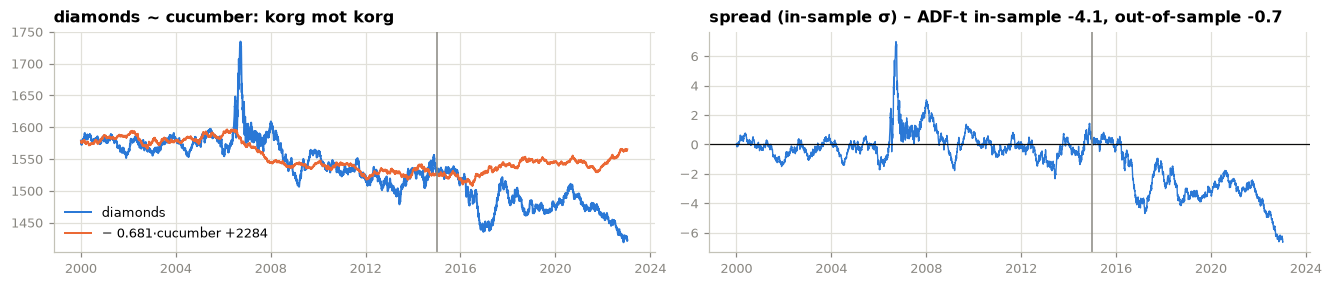

In [12]:
SPREADS = [as_spread(s) for s in MANUAL_SPREADS] if MANUAL_SPREADS else select_spreads(cands, P_IS, **SELECT)
print("Valda spreadar (klistra in som MANUAL_SPREADS för att frysa urvalet):\n", SPREADS)
if SPREADS:
    plot_static_spreads(P, SPREADS, FIT_END)
    plt.show()
else:
    print("Ingen kandidat klarar kraven i SELECT.")

## 5. Strategin

För varje spread $y \sim x$ och varje dag $t$, med enbart data t.o.m. $t$:

1. **Hedge ratio.** Rullande OLS över `beta_window` dagar ger $\beta_t$ och vikterna $w_t = (1, -\beta_t)$.
2. **z-värde.** Spreaden med dagens vikter jämförs med sitt eget medelvärde och sin standardavvikelse de senaste `z_window` dagarna:
   $z_t = w_t^\top (P_t - \mu_t) \big/ \sqrt{w_t^\top \Sigma_t\, w_t}$, där $\mu_t, \Sigma_t$ är prisernas rullande medelvärde och kovarians. Samma vikter används i hela fönstret, så ändringar i $\beta$ ger inga falska hopp i $z$.
3. **Signal.** `band`: sälj spreaden när $z >$ `entry_z`, köp när $z < -$`entry_z`, stäng vid `exit_z`, stop-loss vid `stop_z` (ny affär först när $z$ är tillbaka innanför bandet). `linear`: position $\propto -z$, noll innanför `exit_z`, full vid `entry_z`.
4. **Storlek.** Signalen delas med spreadens dagliga volatilitet (`vol_window`), så att varje spread bär samma risk. Position per tillgång = signal · $w_t$ / vol.
5. **Portföljrisk.** Summan över alla spreadar skalas till konstant förväntad risk: den delas med standardavvikelsen av vad *dagens* portfölj skulle ha tjänat var och en av de senaste `risk_window` dagarna. Det är ekv. (3) i instruktionerna, men med dagens positioner i stället för de historiska – en strategi som går in och ur affärer får annars fel riskskattning. Jämn risk håller nere kurtosis, som straffas hårt i justerad Sharpe: $S_{adj} = S\,(1 + \tfrac{S}{6}\,\text{skew} - \tfrac{S^2}{24}(\text{kurt}-3))$.

**Vilka spreadar?** `SELECTION = "fixed"` handlar spreadarna från avsnitt 4 hela tiden. Urvalet har då sett in-sample-perioden, så bara out-of-sample-kolumnen är ett ärligt test. `"walkforward"` gör om urvalet var `REFIT_EVERY`:e dag på de `FIT_WINDOW` dagarna närmast före och är kausalt rakt igenom.

**Så läser du tabellen** (räknad från första affären): `adjusted_sharpe` out-of-sample är måttet som räknas. Stort gap mellan `sharpe_ex_slippage` och `sharpe` = för mycket handel. Stort gap mellan `sharpe` och `sharpe_1d_lag` = signalen är för kortlivad för tvådagarslaggen. En tydligt negativ Sharpe betyder att spreadarna trendar i stället för att återgå.

In [13]:
def rolling_mean_cov(X, window, min_obs=250):
    """Rullande medelvärde (T×m) och kovarians (T×m×m) över de senaste `window` dagarna (None = all historik).
    Rad t använder bara data t.o.m. t; NaN tills fönstret är fullt (min_obs dagar för all historik)."""
    c = X - X[0]                                                  # centrera kring första observationen (numerisk stabilitet)
    s1, s2 = np.cumsum(c, axis=0), np.cumsum(c[:, :, None] * c[:, None, :], axis=0)
    n = np.arange(1.0, len(X) + 1)
    if window is not None:
        s1[window:], s2[window:] = s1[window:] - s1[:-window], s2[window:] - s2[:-window]
        n = np.minimum(n, window)
    mean = s1 / n[:, None]
    cov = s2 / n[:, None, None] - mean[:, :, None] * mean[:, None, :]
    mean += X[0]
    too_short = n < (min_obs if window is None else window)
    mean[too_short], cov[too_short] = np.nan, np.nan
    return mean, cov


def band_signal(z, entry, exit_, stop):
    """Läge i spreaden (+1 köpt, −1 såld, 0 ute) med hysteres: in vid |z| > entry, ut vid ±exit, stop vid |z| > stop."""
    stop = np.inf if stop is None else stop
    pos, state, armed = np.zeros(len(z)), 0, True
    for t, zt in enumerate(z):
        if np.isnan(zt):
            state = 0
            continue
        if state == 1 and (zt >= -exit_ or zt < -stop):          # köpt spread: mål nått eller stop
            state, armed = 0, zt >= -stop
        elif state == -1 and (zt <= exit_ or zt > stop):         # såld spread: mål nått eller stop
            state, armed = 0, zt <= stop
        armed = armed or abs(zt) < entry                          # efter stop: vänta tills z är innanför bandet igen
        if state == 0 and armed and entry < abs(zt) <= stop:
            state = -1 if zt > 0 else 1
        pos[t] = state
    return pos


def linear_signal(z, entry, exit_, stop):
    """Kontinuerlig position: 0 för |z| ≤ exit, linjärt till ±1 vid |z| ≥ entry, 0 bortom stop."""
    size = np.clip((np.abs(z) - exit_) / max(entry - exit_, 1e-9), 0, 1)
    if stop is not None:
        size = np.where(np.abs(z) > stop, 0, size)
    return np.nan_to_num(-np.sign(z) * size)


def spread_positions(P, spread, p, traded):
    """Positioner (T × antal serier), z-värde (T) och signal (T) för EN spread y ~ xs. Allt är kausalt (data t.o.m. dag t)."""
    cols = [spread[0], *spread[1]]
    X_all = P[cols].to_numpy()
    start = int(np.argmax(~np.isnan(X_all).any(axis=1)))          # första dagen då alla serier finns
    X = X_all[start:]
    T, m = X.shape
    with np.errstate(divide="ignore", invalid="ignore"):
        # 1) hedge ratio: rullande OLS  y = α + β·x  →  spreadvikter w = (1, −β)
        _, cov = rolling_mean_cov(X, p["beta_window"])
        ok = ~np.isnan(cov[:, 0, 0])
        A = cov[ok][:, 1:, 1:]
        ridge = 1e-10 * np.trace(A, axis1=1, axis2=2) / (m - 1) + 1e-12
        beta = np.full((T, m - 1), np.nan)
        beta[ok] = np.linalg.solve(A + ridge[:, None, None] * np.eye(m - 1), cov[ok][:, 1:, :1])[:, :, 0]
        w = np.column_stack([np.ones(T), -beta])
        # 2) z-värde: spreaden med dagens vikter mot sitt medel/std de senaste z_window dagarna
        mean, cov = rolling_mean_cov(X, p["z_window"])
        z = np.einsum("ti,ti->t", w, X - mean) / np.sqrt(np.einsum("ti,tij,tj->t", w, cov, w))
        # 3) signal i spreadenheter
        signal = (band_signal if p["signal"] == "band" else linear_signal)(z, p["entry_z"], p["exit_z"], p["stop_z"])
        # 4) storlek: 1 / spreadens dagliga vol. Icke-handlade serier får vikt 0 (ingen position, ingen PnL)
        w_traded = w * np.isin(cols, traded)
        _, cov_d = rolling_mean_cov(np.diff(X, axis=0, prepend=X[:1]), p["vol_window"])
        vol = np.sqrt(np.einsum("ti,tij,tj->t", w_traded, cov_d, w_traded))
        pos = np.nan_to_num(signal[:, None] * w_traded / vol[:, None], posinf=0.0, neginf=0.0)
    pad = np.zeros(start)
    return np.vstack([np.zeros((start, m)), pos]), np.r_[pad * np.nan, z], np.r_[pad, signal]


def risk_scale(X, P, window, max_leverage=2.0):
    """Skalfaktor som ger portföljen konstant förväntad risk: 1 / std av vad DAGENS positioner skulle ha tjänat var och en
    av de senaste `window` dagarna (ekv. 3 i instruktionerna, fast med dagens portfölj). Skalar aldrig upp mer än max_leverage."""
    changes = P[X.columns].diff().fillna(0.0).to_numpy()
    hypothetical = np.einsum("tn,tnw->tw", X.to_numpy()[window - 1:], sliding_window_view(changes, window, axis=0))
    risk = np.r_[np.full(window - 1, np.nan), np.sqrt((hypothetical**2).mean(axis=1))]
    with np.errstate(divide="ignore"):
        return pd.Series(np.minimum(1 / risk, max_leverage), index=X.index)


def run_strategy(P, schedule, p, traded, details=False):
    """Summerar spreadarnas positioner enligt schedule = [(första rad, sista rad exkl., [spreadar]), ...] och riskskalar.
    Returnerar positioner (DataFrame, 0 = ingen position). details=True ger även positioner per spread samt z-värde/signal."""
    T, cache, parts, on = len(P), {}, {}, {}
    for i0, i1, spreads in schedule:
        for s in spreads:
            if s not in cache:
                cache[s] = spread_positions(P, s, p, traded)
                parts[s], on[s] = np.zeros((T, len(traded))), np.zeros(T, dtype=bool)
            members = [c for c in (s[0], *s[1]) if c in traded]
            src, dst = [(s[0], *s[1]).index(c) for c in members], [traded.index(c) for c in members]
            parts[s][i0:i1, dst] += cache[s][0][i0:i1, src]
            on[s][i0:i1] = True
    X = pd.DataFrame(sum(parts.values(), np.zeros((T, len(traded)))), index=P.index, columns=traded)
    scale = risk_scale(X, P, p["risk_window"]) if p["risk_window"] else pd.Series(1.0, index=P.index)
    X = X.mul(scale, axis=0).fillna(0.0)
    if not details:
        return X
    parts = {s: pd.DataFrame(a, index=P.index, columns=traded).mul(scale, axis=0).fillna(0.0) for s, a in parts.items()}
    diag = {s: pd.DataFrame({"z": cache[s][1], "signal": cache[s][2] * on[s]}, index=P.index) for s in cache}
    return X, parts, diag


def build_schedule(P, traded, mode, fit_end, screen, select, manual=None, fit_window=1000, refit_every=250):
    """Vilka spreadar som handlas när. fixed: ett urval på data t.o.m. fit_end.
    walkforward: nytt urval var refit_every:e dag på de fit_window dagarna närmast före (ingen framtida data)."""
    T = len(P)
    pick = lambda fit: select_spreads(screen_spreads(fit, traded=traded, **screen), fit, **select)
    if manual:
        return [(0, T, [as_spread(s) for s in manual])]
    if mode == "fixed":
        return [(0, T, pick(P.loc[:fit_end]))]
    return [(i, min(i + refit_every, T), pick(P.iloc[i - fit_window:i])) for i in range(fit_window, T, refit_every)]

In [14]:
KEYS = ["adjusted_sharpe", "sharpe", "sharpe_ex_slippage", "sharpe_1d_lag", "av_holding", "skewness", "kurtosis", "position_bias"]


def to_pl(df):
    """pandas (datumindex) → polars i Lynx-format."""
    return pl.from_pandas(df.reset_index()).with_columns(pl.col(DATE).cast(pl.Date))


def used(X):
    """Positionerna utan kolumner som aldrig handlas (evaluation.py delar annars 0/0 per instrument)."""
    return X.loc[:, (X != 0).any()]


def key_figures(X, P, start=None, end=None, keys=KEYS, cost=-0.02):
    """Lynx nyckeltal (evaluation.py) för positionerna X på perioden [start, end], tidigast från första affären."""
    live = X.index[(X != 0).any(axis=1)]
    if len(live) == 0:
        return dict.fromkeys(keys, np.nan)
    Xp = X.loc[live[0] if start is None else max(pd.Timestamp(start), live[0]):end]
    if not (Xp != 0).any().any():
        return dict.fromkeys(keys, np.nan)
    return evaluation.calc_key_figures(to_pl(Xp), to_pl(P[list(X.columns)]), costs=cost, key_figures=list(keys))


def figure_table(X, P, periods, cost=-0.02):
    return pd.DataFrame({name: key_figures(X, P, s, e, cost=cost) for name, (s, e) in periods.items()}).reindex(KEYS)


def net_returns(X, P, cost=-0.02):
    """Daglig avkastning efter kostnader enligt evaluation.py, som pandas-serie."""
    if not (X != 0).any().any():
        return pd.Series(0.0, index=X.index)
    out = evaluation.calc_key_figures(to_pl(X), to_pl(P[list(X.columns)]), costs=cost, key_figures=["returns"])["returns"]
    return pd.Series(out["returns"].to_numpy(), index=pd.DatetimeIndex(out[DATE].to_numpy())).reindex(X.index).fillna(0.0)


def plot_pnl(X, P, parts=None, fit_end=None, cost=-0.02, title=""):
    """Kumulerad avkastning efter kostnader: hela strategin och (om flera) varje spread för sig."""
    fig, ax = plt.subplots(figsize=(11, 3.8))
    parts = parts if parts and len(parts) > 1 else {}
    for k, (s, Xs) in enumerate(list(parts.items())[:7]):
        ax.plot(net_returns(Xs, P, cost).cumsum(), color=COLORS[k + 1], lw=1.0, label=spread_name(s))
    ax.plot(net_returns(X, P, cost).cumsum(), color=COLORS[0], lw=1.8, label="hela strategin")
    ax.axhline(0, color=INK, lw=0.8)
    if fit_end is not None:
        ax.axvline(fit_end, color=MUTED, lw=1)
    ax.set_title(title or "Kumulerad avkastning efter kostnader")
    if parts:
        ax.legend(**OUTSIDE)
    return fig

,hela,in-sample,out-of-sample
adjusted_sharpe,-0.21,-0.13,-0.34
sharpe,-0.21,-0.13,-0.35
sharpe_ex_slippage,-0.19,-0.11,-0.33
sharpe_1d_lag,-0.19,-0.13,-0.30
av_holding,45.79,44.49,47.85
skewness,-0.06,-0.10,0.00
kurtosis,4.87,5.20,4.27
position_bias,0.21,0.13,0.33


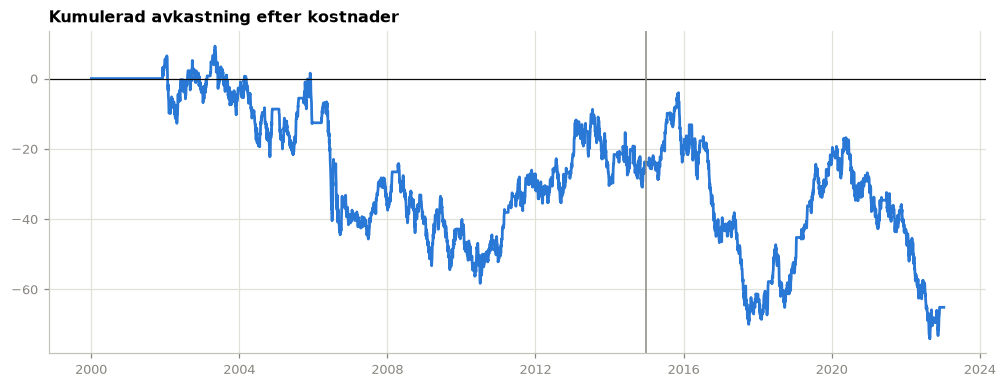

In [15]:
def make_positions(P, params=None):
    """Hela kedjan data → positioner (urval + strategi). Samma funktion används i läckagetestet."""
    schedule = build_schedule(P, TRADED, SELECTION, FIT_END, SCREEN, SELECT, MANUAL_SPREADS, FIT_WINDOW, REFIT_EVERY)
    return run_strategy(P, schedule, params or PARAMS, TRADED)


SCHEDULE = build_schedule(P, TRADED, SELECTION, FIT_END, SCREEN, SELECT, MANUAL_SPREADS, FIT_WINDOW, REFIT_EVERY)
assert any(spreads for *_, spreads in SCHEDULE), (
    "Inga spreadar att handla: ingen kandidat klarar kraven i SELECT. Höj max_margin (np.inf = ta alltid top_k) "
    "eller ange MANUAL_SPREADS om du vill testa strategin ändå.")
if len(SCHEDULE) > 1:
    display(pd.DataFrame([{"från": P.index[i0].date(), "till": P.index[i1 - 1].date(),
                           "spreadar": ", ".join(map(spread_name, spreads)) or "–"} for i0, i1, spreads in SCHEDULE]))

X, parts, diag = run_strategy(P, SCHEDULE, PARAMS, TRADED, details=True)
display(figure_table(X, P, PERIODS, COST).round(2))
if len(parts) > 1:
    print("Sharpe per spread:")
    display(pd.DataFrame({spread_name(s): figure_table(Xs, P, PERIODS, COST).loc["sharpe"] for s, Xs in parts.items()}).T.round(2))
plot_pnl(X, P, parts, FIT_END, COST)
plt.show()

z-värdet som strategin faktiskt handlar på (rullande hedge ratio), med `entry_z`-gränserna och skuggning när spreaden är köpt (blå) eller såld (röd).

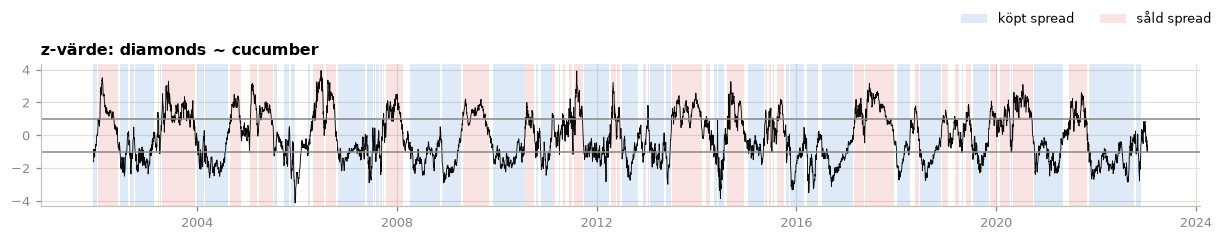

In [16]:
shown = list(diag)[:4]
fig, axes = plt.subplots(len(shown), 1, figsize=(11, 2.1 * len(shown)), squeeze=False, sharex=True, layout="constrained")
for ax, s in zip(axes[:, 0], shown):
    z, signal = diag[s]["z"], diag[s]["signal"]
    lim = 1.05 * np.nanmax([z.abs().max(), PARAMS["entry_z"]])
    ax.fill_between(z.index, -lim, lim, where=signal > 0, color=COLORS[0], alpha=0.15, lw=0, label="köpt spread")
    ax.fill_between(z.index, -lim, lim, where=signal < 0, color=COLORS[7], alpha=0.15, lw=0, label="såld spread")
    ax.plot(z, color=INK, lw=0.6)
    for level in (-PARAMS["entry_z"], PARAMS["entry_z"]):
        ax.axhline(level, color=MUTED, lw=1)
    ax.set_ylim(-lim, lim)
    ax.set_title(f"z-värde: {spread_name(s)}")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper right", ncol=2)
plt.show()

Lynx egen översikt (hela perioden):

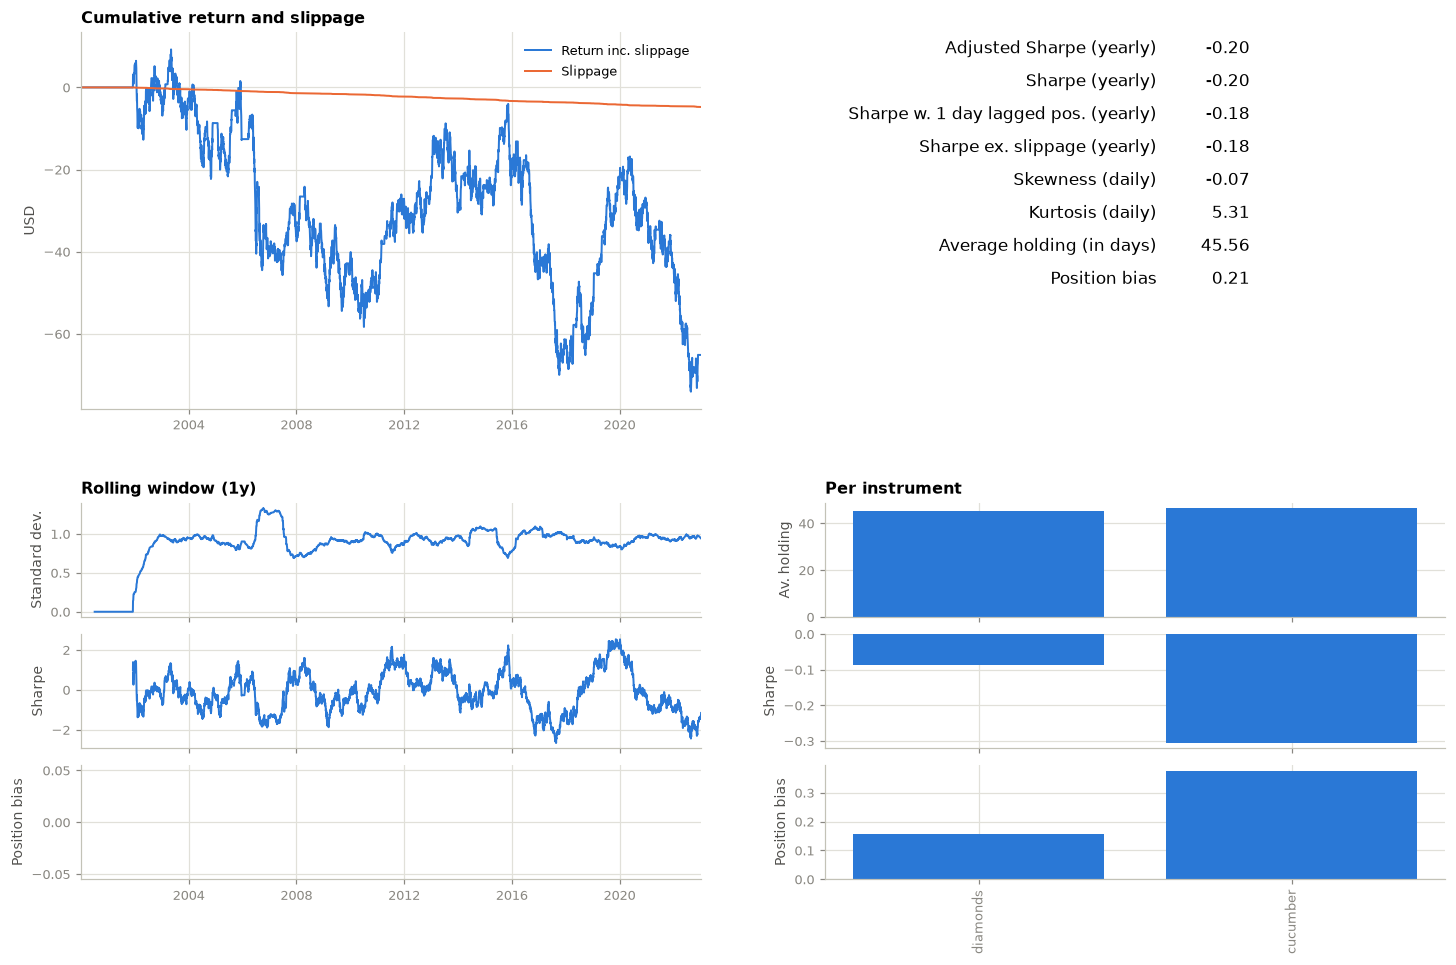

In [17]:
display(evaluation.plot_key_figures(to_pl(used(X)), to_pl(P[list(used(X).columns)]), costs=COST))

### Episodanalys: när spreaden når nivå X, kommer den tillbaka till nivå Y? Och hur lång tid tar det?

Halveringstiden i avsnitt 4 är **ett genomsnitt**. Här ser vi **varje enskild episod** för en vald spread:

1. **Start:** z-värdet passerar ±`entry_z` (nivå **X**) inifrån.
2. **Slut:** z-värdet når tillbaka till `exit_z` (nivå **Y**, 0 = medelvärdet), eller går vidare till ±`stop_z` (stop), eller så tar tiden slut efter `max_days`.
3. Nästa episod kan bara börja när den förra är slut och z har varit innanför ±X igen.

För varje episod räknas **vad affären hade gett**, med samma regler som strategin:
- Signal dag t, in dag t+1, ut dagen efter att Y nås.
- Hedge ratio fryst vid start.
- Kostnad enligt `COST`.

Resultatet visas i **dagliga standardavvikelser av spreaden** vid starten. +1 betyder alltså att affären tjänade en normal dagsrörelse. z-värdet och vikterna är exakt samma som strategin handlar på (rullande, kausalt).

**Viktigt: att z når Y är inte samma sak som vinst.** z mäts mot ett *rullande* medelvärde (`z_window` dagar). z kan därför komma tillbaka till 0 genom att **medelvärdet flyttar sig mot spreaden**, i stället för att spreaden går tillbaka. Då har affären förlorat trots att den "nådde Y". Raden *nådde Y men förlust* visar hur ofta det händer. Titta också på *snitt netto, stop/tidsgräns*: några få stora förluster kan äta upp många små vinster.

**Väntevärdet** = genomsnittlig vinst per episod efter kostnad. För att strategin ska vara värd att handla ska det vara positivt **out-of-sample**, med ett t-värde som helst är över cirka 2. Spreadarna i avsnitt 4 valdes på in-sample-data, så in-sample-siffrorna ser alltid bättre ut än de är.

**Använd:** välj spread och nivåer med reglagen, eller anropa direkt, till exempel
`show_episodes(("butter", ("cars",)), entry_z=2.0, exit_z=0.0)`.

In [18]:
OUTCOME_COLOR = {"nådde Y": COLORS[2], "stop": COLORS[7], "förluststopp": "#8a1f1c", "tidsgräns": COLORS[3],
                 "pågår": MUTED}


def spread_state(P, spread, p):
    """Samma beräkning som spread_positions: rullande vikter w (T×m), z-värde (T), spreadens dagliga vol (T)
    och varje series dagliga vol (T×m). Allt kausalt; NaN innan fönstren är fulla."""
    cols = [spread[0], *spread[1]]
    X_all = P[cols].to_numpy()
    start = int(np.argmax(~np.isnan(X_all).any(axis=1)))
    X = X_all[start:]
    T, m = X.shape
    with np.errstate(divide="ignore", invalid="ignore"):
        _, cov = rolling_mean_cov(X, p["beta_window"])
        ok = ~np.isnan(cov[:, 0, 0])
        A = cov[ok][:, 1:, 1:]
        ridge = 1e-10 * np.trace(A, axis1=1, axis2=2) / (m - 1) + 1e-12
        beta = np.full((T, m - 1), np.nan)
        beta[ok] = np.linalg.solve(A + ridge[:, None, None] * np.eye(m - 1), cov[ok][:, 1:, :1])[:, :, 0]
        w = np.column_stack([np.ones(T), -beta])
        mean, cov = rolling_mean_cov(X, p["z_window"])
        z = np.einsum("ti,ti->t", w, X - mean) / np.sqrt(np.einsum("ti,tij,tj->t", w, cov, w))
        _, cov_d = rolling_mean_cov(np.diff(X, axis=0, prepend=X[:1]), p["vol_window"])
        vol_spread = np.sqrt(np.einsum("ti,tij,tj->t", w, cov_d, w))
        vol_each = np.sqrt(np.einsum("tii->ti", cov_d))
    pad = lambda a: np.concatenate([np.full((start, *a.shape[1:]), np.nan), a])
    return pad(X), pad(w), pad(z), pad(vol_spread), pad(vol_each)


def spread_episodes(P, spread, entry_z=2.0, exit_z=0.0, stop_z=None, max_days=250, params=None, cost=COST,
                    stop_loss=None):
    """En rad per episod: z passerar ±entry_z inifrån → tillbaka vid exit_z ('nådde Y'), ±stop_z ('stop'),
    orealiserad förlust ≥ stop_loss ('förluststopp'), max_days ('tidsgräns') eller slutet av datan ('pågår').
    Vinsten räknas som en affär med strategins tidskonvention: signal dag t, in dag t+1, ut dagen efter slutet,
    vikter frysta vid start. Enhet: spreadens dagliga std vid start. 'värsta_läge' = lägsta orealiserade resultat."""
    p = {**PARAMS, **(params or {})}
    spread = as_spread(spread)
    X, w, z, vol_spread, vol_each = spread_state(P, spread, p)
    dates, T, rows, t = P.index, len(P), [], 1
    while t < T - 2:
        if np.isnan(z[t]) or np.isnan(z[t - 1]) or not abs(z[t]) > entry_z >= abs(z[t - 1]):
            t += 1
            continue
        d = np.sign(z[t])                                      # +1: spreaden är hög → sälj, −1: låg → köp
        end, outcome, worst = None, None, 0.0
        per_unit = -d * w[t] / vol_spread[t]                  # resultat per prisrörelse, i spreadens dagliga std
        for u in range(t + 1, min(t + max_days, T - 2) + 1):
            unrealized = per_unit @ (X[u] - X[t + 1])          # känt vid stängning dag u (in till priset dag t+1)
            worst = min(worst, unrealized)
            if stop_loss is not None and unrealized <= -stop_loss:
                end, outcome = u, "förluststopp"              # beslut dag u, ut dag u+1 (kan bli sämre än nivån)
                break
            if np.isnan(z[u]):
                continue
            if d * z[u] <= exit_z:
                end, outcome = u, "nådde Y"
                break
            if stop_z is not None and d * z[u] >= stop_z:
                end, outcome = u, "stop"
                break
        if end is None:
            end = min(t + max_days, T - 2)
            outcome = "tidsgräns" if end - t >= max_days else "pågår"
        gross = per_unit @ (X[end + 1] - X[t + 1])
        trade_cost = 2 * abs(cost) * np.abs(w[t]) @ vol_each[t] / vol_spread[t]   # in + ut, som evaluation.py
        path = d * z[t:end + 1]
        rows.append({"start": dates[t], "slut": dates[end], "riktning": "såld" if d > 0 else "köpt",
                     "z_start": z[t], "utfall": outcome, "dagar": end - t, "värsta_z": np.nanmax(path),
                     "värsta_läge": min(worst, gross),
                     "brutto": gross, "kostnad": trade_cost, "netto": gross - trade_cost})
        t = end + 1
    return pd.DataFrame(rows)


def episode_summary(ep, periods=None):
    """Nyckeltal per period (efter episodens startdag). 'pågår' räknas inte in."""
    periods = periods or PERIODS
    out = {}
    for name, (a, b) in periods.items():
        e = ep[(ep.utfall != "pågår") & (ep.start >= (a or ep.start.min())) & (ep.start <= (b or ep.start.max()))] \
            if len(ep) else ep
        n = len(e)
        if n == 0:
            out[name] = {"episoder": 0}
            continue
        hit = e.utfall == "nådde Y"
        se = e.netto.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
        out[name] = {
            "episoder": n,
            "nådde Y": f"{hit.mean():.0%}",
            "stop": f"{e.utfall.isin(['stop', 'förluststopp']).mean():.0%}",
            "tidsgräns": f"{(e.utfall == 'tidsgräns').mean():.0%}",
            "dagar till Y, median": e.dagar[hit].median() if hit.any() else np.nan,
            "dagar till Y, 90 %": e.dagar[hit].quantile(0.9) if hit.any() else np.nan,
            "andel vinstaffärer": f"{(e.netto > 0).mean():.0%}",
            "nådde Y men förlust": f"{(e.netto[hit] <= 0).mean():.0%}" if hit.any() else "–",
            "snitt netto, nådde Y": e.netto[hit].mean() if hit.any() else np.nan,
            "snitt netto, stop/tidsgräns": e.netto[~hit].mean() if (~hit).any() else np.nan,
            "snittvinst (vinnare)": e.netto[e.netto > 0].mean(),
            "snittförlust (förlorare)": e.netto[e.netto <= 0].mean(),
            "VÄNTEVÄRDE per episod": e.netto.mean(),
            "t-värde": e.netto.mean() / se if se else np.nan,
            "vinst per dag i affär": e.netto.sum() / max(e.dagar.sum(), 1),
        }
    return pd.DataFrame(out)


def show_episodes(spread, entry_z=2.0, exit_z=0.0, stop_z=None, max_days=250, params=None, stop_loss=None):
    """Figur + tabell för en spread. stop_z / stop_loss = None stänger av respektive stop."""
    spread = as_spread(spread)
    ep = spread_episodes(P, spread, entry_z, exit_z, stop_z, max_days, params, stop_loss=stop_loss)
    p = {**PARAMS, **(params or {})}
    z = spread_state(P, spread, p)[2]
    if ep.empty:
        print("Inga episoder: sänk entry_z.")
        return ep
    outcome_color = OUTCOME_COLOR

    fig = plt.figure(figsize=(12, 6.6), layout="constrained")
    grid = fig.add_gridspec(2, 3, height_ratios=[1.1, 1])
    ax = fig.add_subplot(grid[0, :])
    lim = 1.05 * np.nanmax(np.abs(z))
    for e in ep.itertuples():
        ax.axvspan(e.start, e.slut, color=outcome_color[e.utfall], alpha=0.25, lw=0)
    ax.plot(P.index, z, color=INK, lw=0.6)
    for level, style in [(entry_z, "-"), (-entry_z, "-"), (exit_z, "--"), (-exit_z, "--")]:
        ax.axhline(level, color=MUTED, lw=1, ls=style)
    if stop_z is not None:
        for level in (stop_z, -stop_z):
            ax.axhline(level, color=COLORS[7], lw=1, ls=":")
    ax.axvline(FIT_END, color=INK, lw=1)
    ax.set_ylim(-lim, lim)
    ax.set_title(f"{spread_name(spread)}: z-värde och episoder (X = ±{entry_z:g}, Y = {exit_z:g}"
                 + (f", stop = ±{stop_z:g})" if stop_z is not None else ", ingen stop)"))
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.4, label=k) for k, c in outcome_color.items()
               if k in set(ep.utfall)]
    ax.legend(handles=handles, **OUTSIDE)

    done = ep[ep.utfall != "pågår"]
    oos = done.start > FIT_END
    ax1 = fig.add_subplot(grid[1, 0])
    days = np.arange(0, max_days + 1)
    for label, sel, color in [("in-sample", ~oos, COLORS[0]), ("out-of-sample", oos, COLORS[1])]:
        e = done[sel]
        if len(e):
            reached = np.array([((e.utfall == "nådde Y") & (e.dagar <= d)).mean() for d in days])
            ax1.plot(days, reached, color=color, label=f"{label} (n={len(e)})")
    ax1.set_ylim(0, 1)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax1.set_xlabel("dagar efter start")
    ax1.set_title("Andel som nått Y inom d dagar")
    ax1.legend(loc="lower right")

    ax2 = fig.add_subplot(grid[1, 1])
    hit = done[done.utfall == "nådde Y"]
    if len(hit):
        ax2.hist(hit.dagar, bins=min(25, max(5, len(hit) // 2)), color=COLORS[2], alpha=0.7)
        ax2.axvline(hit.dagar.median(), color=INK, ls="--", label=f"median {hit.dagar.median():.0f} d")
        ax2.legend()
    ax2.set_xlabel("dagar")
    ax2.set_title("Tid från X till Y")

    ax3 = fig.add_subplot(grid[1, 2])
    bins = np.linspace(done.netto.min(), done.netto.max(), 25) if len(done) > 1 else 10
    for k in ["nådde Y", "stop", "förluststopp", "tidsgräns"]:
        e = done[done.utfall == k]
        if len(e):
            ax3.hist(e.netto, bins=bins, color=outcome_color[k], alpha=0.7, label=k)
    ax3.axvline(0, color=INK, lw=0.8)
    ax3.axvline(done.netto.mean(), color=INK, ls="--", lw=1.5, label=f"väntevärde {done.netto.mean():+.2f}")
    ax3.set_xlabel("netto per episod (dagliga std)")
    ax3.set_title("Vinst per episod")
    ax3.legend(fontsize=7.5)
    plt.show()
    display(episode_summary(ep).round(2))
    return ep


# Kontroll: z-värdet här är exakt det strategin handlar på
_s = SPREADS[0] if SPREADS else as_spread((P.columns[0], (P.columns[1],)))
assert np.allclose(spread_state(P, _s, PARAMS)[2], spread_positions(P, _s, PARAMS, TRADED)[1], equal_nan=True)

In [19]:
EPISODE_SPREADS = list(dict.fromkeys(
    SPREADS + [as_spread((r.y, r.xs)) for r in cands.head(10).itertuples()]
    + [as_spread((a, (b,))) for a, b in combinations(TRADED, 2)]))

try:
    import ipywidgets as widgets
except ImportError:
    episodes = show_episodes(EPISODE_SPREADS[0], entry_z=2.0, exit_z=0.0)
else:
    def _episodes_ui(spread, entry_z, exit_z, stop_z, max_days):
        show_episodes(spread, entry_z, exit_z, None if stop_z == 0 else stop_z, max_days)

    slider = dict(continuous_update=False, style={"description_width": "initial"})
    widgets.interact(
        _episodes_ui,
        spread=widgets.Dropdown(options=[(spread_name(s), s) for s in EPISODE_SPREADS], description="spread"),
        entry_z=widgets.FloatSlider(value=2.0, min=0.5, max=4.0, step=0.25, description="X: start vid |z| >", **slider),
        exit_z=widgets.FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.25, description="Y: mål vid z =", **slider),
        stop_z=widgets.FloatSlider(value=0.0, min=0.0, max=8.0, step=0.5, description="stop vid |z| > (0 = av)", **slider),
        max_days=widgets.IntSlider(value=250, min=10, max=750, step=10, description="max dagar", **slider),
    )

interactive(children=(Dropdown(description='spread', options=(('diamonds ~ cucumber', ('diamonds', ('cucumber'…

### Förlustsidan: vad händer när spreaden *inte* går tillbaka, och vad gör en stop?

Episodanalysen ovan visar mest vinstsidan. Här syns **båda sidorna** för en spread och en stopnivå (failsafe):

- **Stopptyp `förlust`:** stäng när den orealiserade förlusten når `stop` dagliga std. Det begränsar förlusten direkt.
- **Stopptyp `z`:** stäng när |z| passerar `stop`, som `stop_z` i strategin. Det slår sällan till, eftersom z mäts mot ett rullande medelvärde som följer efter spreaden.

En stop **utlöses vid stängning och utförs dagen efter**, precis som strategin handlar. Förlusten kan därför bli större än stopnivån.

**Figurerna**
1. **Varje episod som en stapel** (i tidsordning). Stapeln är slutresultatet, och det svarta strecket visar **hur djupt affären gick** innan den avslutades. Långa streck under en grön stapel betyder att affären var djupt minus innan den vände.
2. **Hur djupt gick affären mot hur slutade den** (utan stop). Allt till vänster om stoplinjen skulle ha stoppats. Röda punkter till vänster är **förluster som stoppen begränsar**. Gröna punkter till vänster är **vinnare som stoppen skulle ha klippt**. Det är priset för skyddet.
3. **Väntevärde mot stopnivå**, in-sample och out-of-sample. Leta efter en nivå som hjälper i båda perioderna.

**Använd:** reglagen nedan, eller till exempel `show_risk(("butter", ("cars",)), entry_z=2.0, exit_z=0.0, stop_type="förlust", stop=10)`.

In [20]:
def stop_levels(stop_type, entry_z):
    return [None] + ([entry_z + k for k in (0.5, 1.0, 1.5, 2.0, 3.0, 4.0)] if stop_type == "z"
                     else [2.0, 3.0, 5.0, 7.5, 10.0, 15.0, 20.0, 30.0])


def stop_sweep(P, spread, entry_z, exit_z, stop_type, levels=None, max_days=250, params=None):
    """Väntevärde, andel stoppade och förluster för en rad stopnivåer (None = ingen stop)."""
    rows = []
    for level in levels or stop_levels(stop_type, entry_z):
        kw = {"stop_z": level} if stop_type == "z" else {"stop_loss": level}
        done = spread_episodes(P, spread, entry_z, exit_z, max_days=max_days, params=params, **kw)
        done = done[done.utfall != "pågår"]
        stopped = done.utfall.isin(["stop", "förluststopp"])
        row = {"stop": "av" if level is None else f"{level:g}", "episoder": len(done),
               "andel stoppade": stopped.mean(), "snittvinst": done.netto[done.netto > 0].mean(),
               "snittförlust": done.netto[done.netto <= 0].mean(),
               "snittförlust när stoppad": done.netto[stopped].mean() if stopped.any() else np.nan,
               "största förlust": done.netto.min()}
        for name, sel in [("in-sample", done.start <= FIT_END), ("out-of-sample", done.start > FIT_END)]:
            e = done.netto[sel]
            row[f"väntevärde {name}"] = e.mean() if len(e) else np.nan
            row[f"t {name}"] = e.mean() / (e.std(ddof=1) / np.sqrt(len(e))) if len(e) > 1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("stop")


def show_risk(spread, entry_z=2.0, exit_z=0.0, stop_type="förlust", stop=10.0, max_days=250, params=None):
    """Båda sidorna för en spread: vinster, förluster, hur djupt affärerna gick och effekten av en stopnivå.
    stop_type: 'förlust' (orealiserad förlust i dagliga std) eller 'z' (|z|). stop=None = ingen stop."""
    spread = as_spread(spread)
    kw = {"stop_z": stop} if stop_type == "z" else {"stop_loss": stop}
    free = spread_episodes(P, spread, entry_z, exit_z, max_days=max_days, params=params)
    ep = spread_episodes(P, spread, entry_z, exit_z, max_days=max_days, params=params, **kw)
    free, ep = free[free.utfall != "pågår"], ep[ep.utfall != "pågår"]
    if ep.empty:
        print("Inga avslutade episoder: sänk entry_z.")
        return
    sweep = stop_sweep(P, spread, entry_z, exit_z, stop_type, max_days=max_days, params=params)
    stop_text = "ingen stop" if stop is None else (f"förluststopp {stop:g} std" if stop_type == "förlust"
                                                   else f"z-stop ±{stop:g}")

    fig = plt.figure(figsize=(12, 7), layout="constrained")
    grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])

    # 1) varje episod: slutresultat (stapel) och värsta läge (streck)
    ax = fig.add_subplot(grid[0, :])
    x = np.arange(len(ep))
    ax.bar(x, ep.netto, color=[OUTCOME_COLOR[u] for u in ep.utfall], width=0.8)
    ax.vlines(x, ep.värsta_läge, 0, color=INK, lw=1.2, label="värsta läge under affären")
    if stop is not None and stop_type == "förlust":
        ax.axhline(-stop, color="#8a1f1c", ls="--", lw=1, label=f"förluststopp −{stop:g}")
    n_is = int((ep.start <= FIT_END).sum())
    ax.axvline(n_is - 0.5, color=MUTED, lw=1)
    ax.annotate("out-of-sample →", (n_is - 0.5, 1), xycoords=("data", "axes fraction"), xytext=(4, -10),
                textcoords="offset points", fontsize=8, color=MUTED)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_xlabel("episod (i tidsordning)")
    ax.set_ylabel("netto (dagliga std)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=OUTCOME_COLOR[u], label=u) for u in OUTCOME_COLOR if u in set(ep.utfall)]
    ax.legend(handles=handles + ax.get_legend_handles_labels()[0], **OUTSIDE)
    ax.set_title(f"{spread_name(spread)}: X = ±{entry_z:g}, Y = {exit_z:g}, {stop_text}. "
                 f"Väntevärde {ep.netto.mean():+.2f}, största förlust {ep.netto.min():.1f}")

    # 2) hur djupt gick affären mot hur slutade den (utan stop)
    ax = fig.add_subplot(grid[1, 0])
    depth = free.värsta_z if stop_type == "z" else -free.värsta_läge
    winner = free.netto > 0
    ax.scatter(depth[winner], free.netto[winner], s=22, color=COLORS[2], label="vinnare")
    ax.scatter(depth[~winner], free.netto[~winner], s=22, color=COLORS[7], label="förlorare")
    ax.axhline(0, color=INK, lw=0.8)
    if stop is not None:
        hit = depth >= stop
        ax.axvline(stop, color="#8a1f1c", ls="--", lw=1.2)
        ax.axvspan(stop, max(depth.max(), stop) * 1.05, color="#8a1f1c", alpha=0.07)
        ax.set_title(f"Stoppen träffar {hit.sum()} av {len(free)} episoder:\n"
                     f"{(hit & ~winner).sum()} förlorare begränsas, {(hit & winner).sum()} vinnare klipps")
    else:
        ax.set_title("Hur djupt gick affären,\noch hur slutade den? (utan stop)")
    ax.set_xlabel("värsta |z| under affären" if stop_type == "z" else "djupaste orealiserade förlust (dagliga std)")
    ax.set_ylabel("netto utan stop")
    ax.legend(loc="lower left")

    # 3) väntevärde mot stopnivå
    ax = fig.add_subplot(grid[1, 1])
    pos = np.arange(len(sweep))
    for col, color in [("väntevärde in-sample", COLORS[0]), ("väntevärde out-of-sample", COLORS[1])]:
        ax.plot(pos, sweep[col], "o-", color=color, label=col.replace("väntevärde ", ""))
    chosen = "av" if stop is None else f"{stop:g}"
    if chosen in sweep.index:
        ax.axvline(list(sweep.index).index(chosen), color=INK, ls=":", lw=1)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_xticks(pos, sweep.index)
    ax.set_xlabel("stopnivå" + (" (|z|)" if stop_type == "z" else " (dagliga std)"))
    ax.set_ylabel("väntevärde per episod")
    ax2 = ax.twinx()
    ax2.bar(pos, sweep["andel stoppade"], color=MUTED, alpha=0.25, width=0.6)
    ax2.set_ylim(0, 1)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax2.set_ylabel("andel stoppade (staplar)", color=MUTED)
    ax2.grid(False)
    ax.set_title("Väntevärde mot stopnivå")
    ax.legend(loc="lower right")
    plt.show()

    compare = pd.DataFrame({"utan stop": episode_summary(free).loc[:, "hela"],
                            stop_text: episode_summary(ep).loc[:, "hela"]})
    display(compare)
    display(sweep.round(2))

In [21]:
try:
    import ipywidgets as widgets
except ImportError:
    show_risk(EPISODE_SPREADS[0])
else:
    def _risk_ui(spread, entry_z, exit_z, stop_type, stop, max_days):
        show_risk(spread, entry_z, exit_z, stop_type, None if stop == 0 else stop, max_days)

    slider = dict(continuous_update=False, style={"description_width": "initial"})
    widgets.interact(
        _risk_ui,
        spread=widgets.Dropdown(options=[(spread_name(s), s) for s in EPISODE_SPREADS], description="spread"),
        entry_z=widgets.FloatSlider(value=2.0, min=0.5, max=4.0, step=0.25, description="X: start vid |z| >", **slider),
        exit_z=widgets.FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.25, description="Y: mål vid z =", **slider),
        stop_type=widgets.Dropdown(options=["förlust", "z"], value="förlust", description="stopptyp"),
        stop=widgets.FloatSlider(value=10.0, min=0.0, max=30.0, step=0.5, description="stopnivå (0 = av)", **slider),
        max_days=widgets.IntSlider(value=250, min=10, max=750, step=10, description="max dagar", **slider),
    )

interactive(children=(Dropdown(description='spread', options=(('diamonds ~ cucumber', ('diamonds', ('cucumber'…

## 6. Snurra på parametrarna

**Svep.** Två valfria parametrar i `PARAMS` varieras över ett rutnät och justerad Sharpe visas in-sample och out-of-sample. Leta efter breda platåer som finns i *båda* panelerna – en ensam bra ruta är överanpassning. Urvalet av spreadar (`SCHEDULE`) hålls fast; störst effekt brukar `z_window`, `entry_z`/`exit_z` och `beta_window` ha.

In [22]:
def sweep(P, schedule, base, grid, periods, traded, cost=-0.02, key="adjusted_sharpe"):
    """Nyckeltal för alla kombinationer av två parametrar. grid = {namn1: [värden], namn2: [värden]}."""
    (n1, v1), (n2, v2) = grid.items()
    out = {name: pd.DataFrame(np.nan, index=pd.Index(v1, name=n1), columns=pd.Index(v2, name=n2)) for name in periods}
    for a in v1:
        for b in v2:
            X = run_strategy(P, schedule, {**base, n1: a, n2: b}, traded)
            for name, (s, e) in periods.items():
                out[name].loc[a, b] = key_figures(X, P, s, e, [key], cost)[key]
    return out

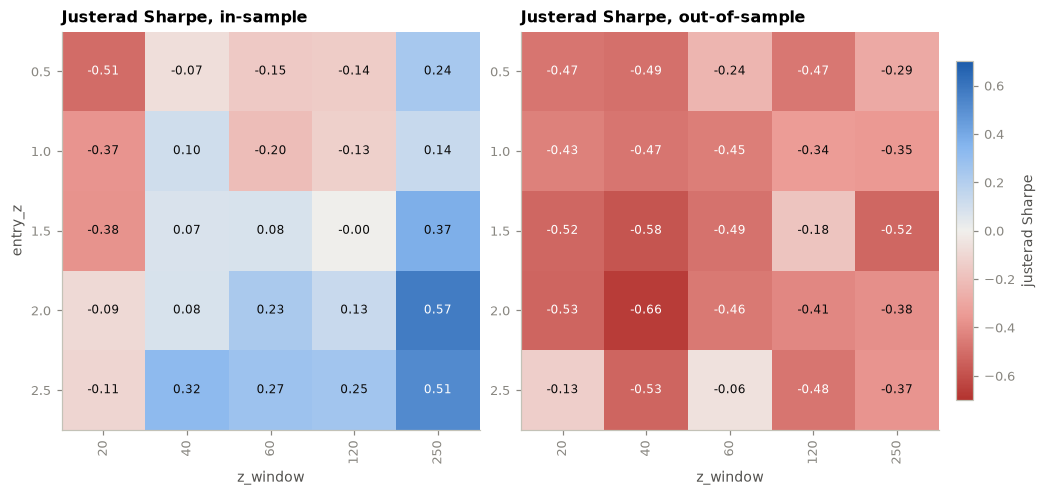

In [23]:
GRID = {"entry_z": [0.5, 1.0, 1.5, 2.0, 2.5], "z_window": [20, 40, 60, 120, 250]}      # byt till valfria två nycklar i PARAMS

res = sweep(P, SCHEDULE, PARAMS, GRID, {k: PERIODS[k] for k in ("in-sample", "out-of-sample")}, TRADED, COST)
fig = plot_heatmaps(list(res.values()), [f"Justerad Sharpe, {k}" for k in res], "justerad Sharpe")
for ax in fig.axes[:2]:
    ax.set_xlabel(list(GRID)[1])
fig.axes[0].set_ylabel(list(GRID)[0])
plt.show()

**Reglage.** Dra i reglagen för att se kurvan och nyckeltalen direkt (kräver en körande kernel och `ipywidgets`, som följer med `jupyter`).

In [24]:
try:
    import ipywidgets as widgets
except ImportError:
    print("ipywidgets saknas – använd svepet ovan eller ändra PARAMS direkt.")
else:
    def explore(entry_z, exit_z, stop_z, z_window, beta_window, signal):
        p = {**PARAMS, "entry_z": entry_z, "exit_z": exit_z, "stop_z": stop_z, "z_window": z_window,
             "beta_window": beta_window, "signal": signal}
        Xp = run_strategy(P, SCHEDULE, p, TRADED)
        t = figure_table(Xp, P, PERIODS, COST).loc["adjusted_sharpe"]
        plot_pnl(Xp, P, None, FIT_END, COST, f"Justerad Sharpe: in-sample {t['in-sample']:.2f}, out-of-sample {t['out-of-sample']:.2f}")
        plt.show()

    slider = dict(continuous_update=False)
    widgets.interact(
        explore,
        entry_z=widgets.FloatSlider(value=PARAMS["entry_z"], min=0.25, max=3.5, step=0.25, **slider),
        exit_z=widgets.FloatSlider(value=PARAMS["exit_z"], min=-2.0, max=1.5, step=0.25, **slider),
        stop_z=widgets.FloatSlider(value=PARAMS["stop_z"] or 6.0, min=2.5, max=6.0, step=0.5, **slider),
        z_window=widgets.IntSlider(value=PARAMS["z_window"], min=10, max=500, step=10, **slider),
        beta_window=widgets.IntSlider(value=PARAMS["beta_window"] or 500, min=60, max=1500, step=20, **slider),
        signal=widgets.Dropdown(options=["band", "linear"], value=PARAMS["signal"]),
    )

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='entry_z', max=3.5, min=0.25…

## 7. Läckagetest och export

Lynx två tester för framåtblickande bias: (1) kör på kortare historik, (2) kör på ett dataset som är identiskt fram till $T$ men annorlunda efteråt. I båda fallen måste positionerna t.o.m. $T$ vara identiska.

**Inför slutkörningen på hela datasetet:** med `SELECTION = "fixed"` får `FIT_END` inte flyttas när out-of-sample-datat läggs till (eller frys urvalet med `MANUAL_SPREADS`). Byt `DATA_PATH`, kör om allt och kontrollera att testet nedan fortfarande är OK.

In [25]:
def leak_test(make_positions, P, cuts=(20, 250), seed=0):
    """Största positionsskillnad t.o.m. dag T när data efter T (a) tas bort, (b) byts ut mot annan data. Ska vara 0."""
    rng = np.random.default_rng(seed)
    full, rows = make_positions(P), []
    for cut in cuts:
        ref = full.iloc[:-cut]
        changed = P.copy()
        changed.iloc[-cut:] = changed.iloc[-cut:] + rng.normal(0, P.diff().std().to_numpy(), (cut, P.shape[1])).cumsum(axis=0)
        row = {"ändrade dagar på slutet": cut}
        for name, Q in (("kortare historik", P.iloc[:-cut]), ("ändrad framtid", changed)):
            row[f"max diff, {name}"] = (make_positions(Q).iloc[: len(ref)] - ref).abs().max().max()
        rows.append(row)
    return pd.DataFrame(rows).set_index("ändrade dagar på slutet")

In [26]:
test = leak_test(make_positions, P)
display(test)
assert test.to_numpy().max() < 1e-9, "LÄCKAGE: positionerna beror på framtida data!"
print("OK – inga positioner ändras av framtida data.")

,"max diff, kortare historik","max diff, ändrad framtid"
ändrade dagar på slutet,,
20,0.0,0.0
250,0.0,0.0


OK – inga positioner ändras av framtida data.


In [27]:
# Tillgångar utan positioner utelämnas (kolumnerna i filen definierar universumet i evaluation.py) och inga celler är tomma.
to_pl(used(X)).write_csv(OUTPUT_PATH)

# Kontroll: läs tillbaka filen som Lynx skulle göra och räkna nyckeltalen på out-of-sample
saved = pl.read_csv(OUTPUT_PATH, try_parse_dates=True)
check = evaluation.calc_key_figures(saved.filter(pl.col(DATE) >= OOS_START.date()), to_pl(P[saved.columns[1:]]), costs=COST)
print(f"Sparade {saved.height} dagar × {saved.width - 1} tillgångar till {OUTPUT_PATH.name}. "
      f"Justerad Sharpe out-of-sample enligt filen: {check['adjusted_sharpe']:.2f}")
saved.tail(3)

Sparade 5956 dagar × 2 tillgångar till pairs_positions.csv. Justerad Sharpe out-of-sample enligt filen: -0.34


AsOfDate,diamonds,cucumber
date,f64,f64
2023-01-09,0.0,0.0
2023-01-10,0.546896,-0.550347
2023-01-11,0.550308,-0.554673


## Bilaga: självtest på syntetisk data

Samma kedja på ett dataset med kända samband, för att se hur ett positivt utfall ser ut: `silver ~ gold` är ett kointegrerat par, `bread ~ wheat + corn` en kointegrerad korg, `copper`/`zinc` är starkt korrelerade men **inte** kointegrerade (en fälla) och `oil` är orelaterad. Här används den strängare tröskeln från slumptestet, så att bara spreadar som slår slumpen handlas.

In [28]:
def make_demo_prices(T=4000, seed=7):
    """Syntetiska priser med ett kointegrerat par, en kointegrerad korg, ett korrelerat-men-inte-kointegrerat par och brus."""
    rng = np.random.default_rng(seed)
    walk = lambda sd: np.cumsum(rng.normal(0, sd, T))

    def ou(half_life, sd):                                        # stationär AR(1) med given halveringstid och std
        phi, x = 0.5 ** (1 / half_life), np.zeros(T)
        eps = rng.normal(0, sd * np.sqrt(1 - phi**2), T)
        for t in range(1, T):
            x[t] = phi * x[t - 1] + eps[t]
        return x

    gold, wheat, corn, copper = walk(3.0), walk(2.0), walk(4.0), walk(3.0)
    prices = {
        "gold": 1500 + gold,
        "silver": 400 + 0.5 * gold + ou(15, 6),                   # silver − 0.5·gold är stationär
        "wheat": 800 + wheat,
        "corn": 600 + corn,
        "bread": 900 + 0.6 * wheat + 0.3 * corn + ou(25, 5),      # bread − 0.6·wheat − 0.3·corn är stationär
        "copper": 1200 + copper,
        "zinc": 700 + 0.8 * copper + walk(1.2),                   # korrelerad med copper, men spreaden är en slumpvandring
        "oil": 1000 + walk(2.5),
    }
    return pd.DataFrame(prices, index=pd.bdate_range("2005-01-03", periods=T, name=DATE))

,n,long,short,adf_t,margin,half_life,rho_1d,rho_20d,adf_t_oos,half_life_oos
0,2,silver,0.497·gold,-6.98,-3.64,15.18,0.63,0.76,-5.67,17.77
1,3,silver,0.51·gold + 0.0395·zinc,-7.15,-3.41,14.54,0.63,0.76,-5.18,21.12
2,3,silver,0.509·gold + 0.0277·copper,-7.08,-3.34,14.80,0.63,0.76,-5.47,19.02
3,3,silver + 0.0321·wheat,0.505·gold,-7.04,-3.30,14.92,0.63,0.76,-5.56,18.63
4,3,silver + 0.013·oil,0.499·gold,-7.01,-3.27,15.03,0.63,0.76,-5.65,17.94
5,3,silver + 0.00589·bread,0.498·gold,-6.99,-3.25,15.15,0.63,0.76,-5.68,17.73


Tröskel för margin: -1.40 → valda spreadar: [('silver', ('gold',)), ('bread', ('wheat', 'corn'))]


,hela,in-sample,out-of-sample
adjusted_sharpe,1.26,1.41,1.10
sharpe,1.27,1.41,1.11
sharpe_ex_slippage,1.38,1.52,1.21
sharpe_1d_lag,1.25,1.35,1.13
av_holding,21.52,20.05,23.52
skewness,0.04,0.06,0.01
kurtosis,3.19,3.16,3.23
position_bias,0.00,0.01,0.00


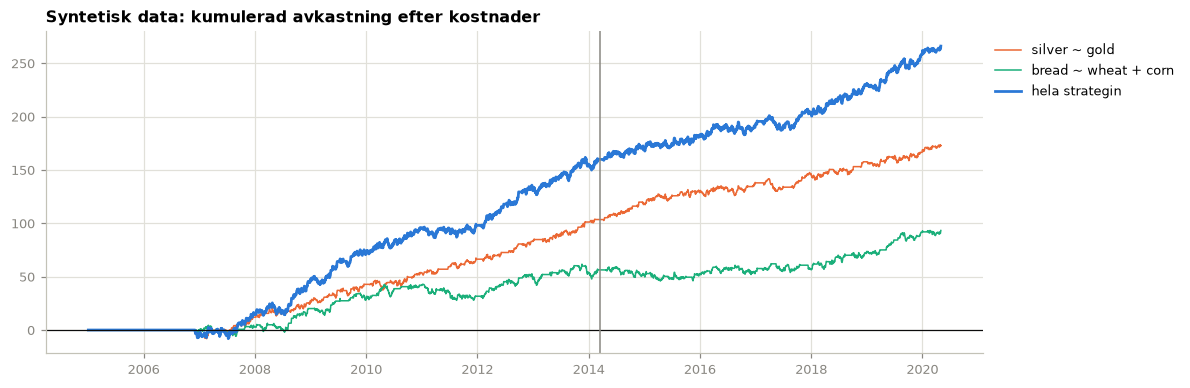

In [29]:
D = make_demo_prices()
D_COLS, D_END = list(D.columns), D.index[int(0.6 * len(D))]
D_IS, D_OOS = D.loc[:D_END], D.loc[D.index > D_END]
display(screen_spreads(D_IS, D_OOS, **SCREEN).drop(columns=["y", "xs", "weights"]).head(6).round(2))

threshold = np.quantile(surrogate_best(D_IS, 30, SELECT["hl_min"], SELECT["hl_max"], **SCREEN), 0.05)
demo_schedule = build_schedule(D, D_COLS, "fixed", D_END, SCREEN, {**SELECT, "max_margin": threshold})
print(f"Tröskel för margin: {threshold:.2f} → valda spreadar: {demo_schedule[0][2]}")

DX, demo_parts, _ = run_strategy(D, demo_schedule, PARAMS, D_COLS, details=True)
demo_periods = {"hela": (None, None), "in-sample": (None, D_END), "out-of-sample": (D_OOS.index[0], None)}
display(figure_table(DX, D, demo_periods, COST).round(2))
plot_pnl(DX, D, demo_parts, D_END, COST, "Syntetisk data: kumulerad avkastning efter kostnader")
plt.show()